# Main notebook for Optics to MRI registration

In [1]:
# Import libraries and functions
from module.utils import *
from module.utils_BRATS import *
from module.main_functions import *


id_patient = 0
Patient_ID_array = np.array(["P_081"])
print("Patient",Patient_ID_array[id_patient])


Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient], RGB_optics=True)


# #####################
# # Path and filenames
# #####################
# main_path = "/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient]

# # main_path_optics = main_path + "/optics_HSI/"  #HSI
# main_path_optics = main_path + "/optics/" # RGB



# Load parameters
params = Params()



params_file = Mypath.main_path+"/Params.json"
if os.path.exists(params_file):
    print("Param file exists")
    params = Params.load(params_file)
else:
    print("Param file does not exist")



Patient P_081
Param file exists


# Extract brain surface

TODO: split brain extraction and surface extraction

In [ ]:
error = main_extract_brain(Mypath, params)
print(error)

error = main_get_surface_mask(Mypath, params)
print(error)

# Plot brain surface

In [ ]:
error, proj = main_plot_extracted_brain(Mypath)

plt.figure(figsize=(30,30))
plt.imshow(proj)

# Get tumor segmentation in T1 space

In [2]:
error = main_get_tumor_segmentation(Mypath)
print(error)


[main_get_tumor_segmentation] Flair file is missing


# [Debug] Test preprocess BRATS segmentation

In [ ]:
main_path = Mypath.main_path
output_dir = Mypath.output_dir


main_path_MRI = main_path + "/MRI/"

filename_t1 = main_path_MRI+"T1.nii"
filename_flair = main_path_MRI+"FLAIR.nii"
filename_t1_bet = output_dir+"r_T1_bet.nii.gz"


#Preprocess data in BRATS space
param_transform_atlas = preprocess_exam_in_brats_style_ITK(filename_t1, filename_flair, filename_t1_bet, output_dir)




#Free GPU cache
torch.cuda.empty_cache()


#Process tumor segmentation
segmenter = AdultGliomaSegmenter()
segmenter.infer_single(
    t1c = output_dir+"r_T1_bet_atlas.nii.gz",
    t1n = output_dir+"r_T1_bet_atlas.nii.gz",
    t2f = output_dir+"r_FLAIR_bet_atlas.nii.gz",
    t2w = output_dir+"r_FLAIR_bet_atlas.nii.gz",
    output_file=output_dir+"segmentation_atlas_space.nii.gz",
    log_file = output_dir+"log.txt"
)


# Registration back to T1 space")
filename_tumor = output_dir+ "segmentation_atlas_space.nii.gz"

register_tumor_segmentation_to_T1_space(output_dir, filename_t1_bet, filename_tumor, param_transform_atlas)

# Register fMRI on T1

A rigid transform is used because fMRI are usually cropped. If an affine transform is used, the registered volume does not fit the brain.

In [ ]:

# params.register_fMRI_to_T1 = True
error = main_register_fMRI_to_T1(Mypath, params)
print(error)


error, slice_T1, slice_fMRI = main_plot_fMRI_T1_registration(Mypath)
print(error)


# Plot overlay of registered slices
plt.figure(figsize=(6,6))
plt.imshow(slice_T1)  # Base image
plt.imshow(slice_fMRI, cmap="hot", alpha=0.5)  # Overlay with transparency
plt.axis("off")
plt.title("Overlay of Registered MRI Slices")
plt.show()





# Rotation of the MRI volume and projection with an angle

1) Load the MRI volumes
2) Calculate the center of gravitiy of the tumor segmenation
3) Calculate a new orthonormal basis. Consider that the vector between the center of mass of the tumor and the origin of MRI is the z axis
4) Calculate rotation matrix between origin basis and the new orthonormal basis
5) Create an affine transform
6) Use the resampling filter to apply the transform
7) Process the projections

Spacing projection [0.4265402853488922, 0.44404974579811096]
Success
Success


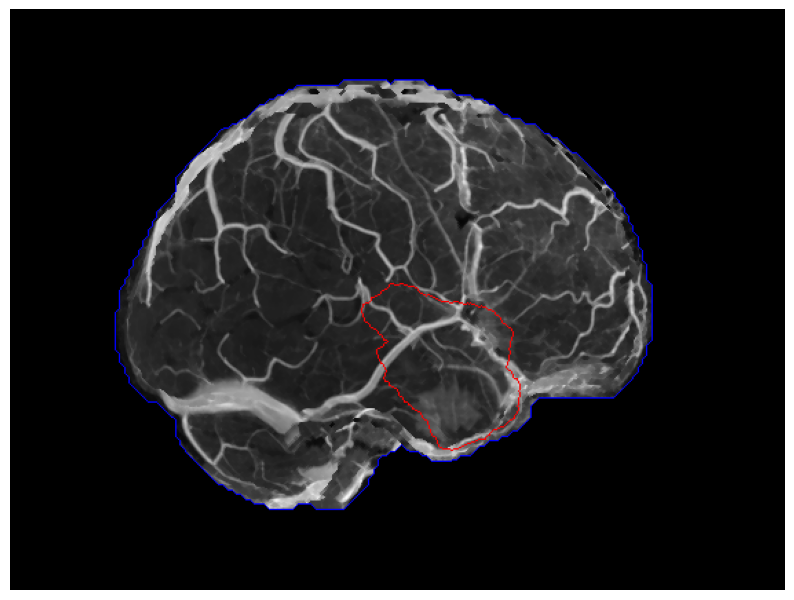

In [2]:
#Get MRI projection
# params.projection_type = "Transverse"
# params.projection_type = "Sagital"
# params.projection_type = "Coronal"
# params.projection_base_axis = "Y axis"

# # params.axis_projection = "Origin MRI" #"Center mass MRI"
error = main_get_MRI_projection(Mypath, params)
print(error)

#Plot projection
error, proj = main_plot_MRI_Projection(Mypath)
print(error)

plt.figure(figsize=(10,10))
plt.imshow(proj)
plt.axis('off')
plt.show()

# Contrast enhancement and blood vessel segmentation

Success
[main_get_vessels_in_optics] Thresholding process
end
Success
Success
(256, 256, 3)
(74, 111, 3)
Success
Success
(256, 256, 3)
(74, 111, 3)
Success


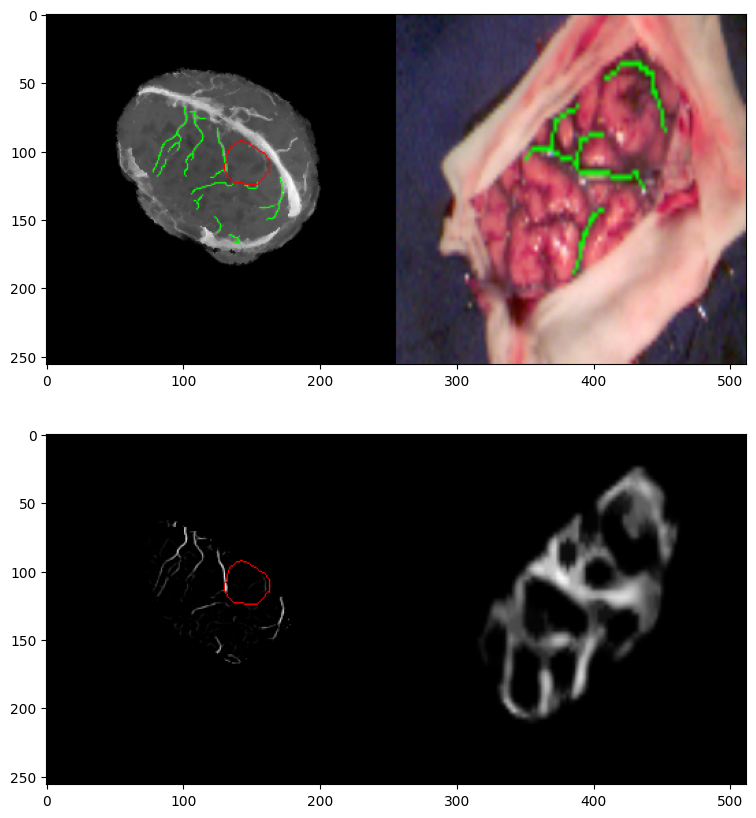

In [2]:
#get skeleton vessel in MRI projection
# params.sigma_minimum_mm_MRI = 0
# params.sigma_maximum_mm_MRI = 1
# params.thresh_MRI = 10
error = main_get_vessels_in_MRI(Mypath, params)
print(error)

# #get skeleton vessel in Optical image
# params.sigma_minimum_mm_optics =  3
# params.sigma_maximum_mm_optics = 3
# params.thresh_optics = 100
# params.ksize_mm_kernal_specular_reflection_optics = 2

error = main_get_vessels_in_optics(Mypath, params)
print(error)

error,display = main_plot_vessel_skeletons(Mypath, params)
print(error)

plt.figure(figsize=(10,10))
plt.subplot(211)
plt.imshow(display)

error,display = main_plot_Frangi_images(Mypath, params)
print(error)

plt.subplot(212)
plt.imshow(display)
plt.show()



# Plot blood vessel segmentation

Success
(512, 512, 3)
(94, 155, 3)


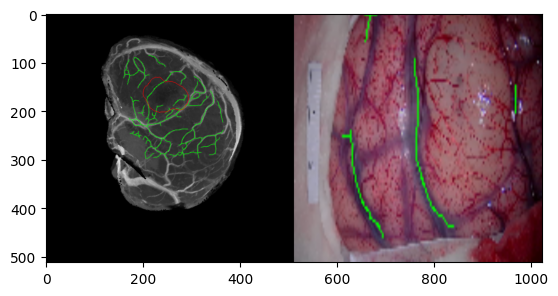

Success
(512, 512, 3)
(94, 155, 3)
Success


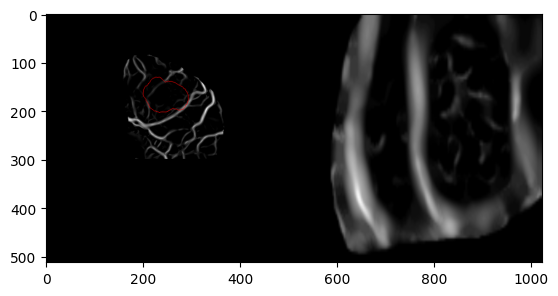

In [13]:
error,display = main_plot_vessel_skeletons(Mypath, params)

plt.figure()
plt.imshow(display)
plt.show()

error,display = main_plot_Frangi_images(Mypath, params)
print(error)

plt.figure()
plt.imshow(display)
plt.show()

# [Debug] set MRI and Optics keypoints on Blood vessel

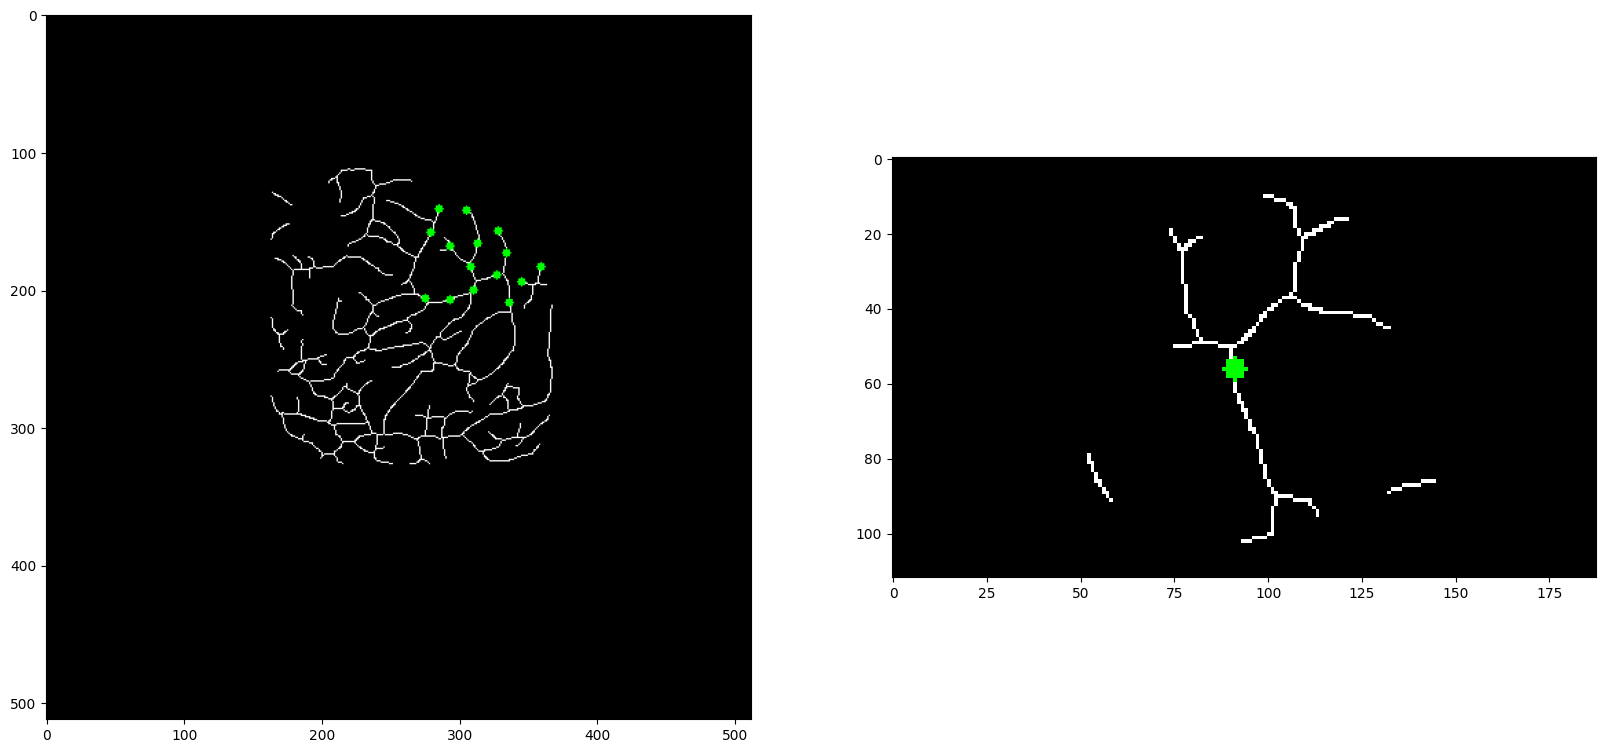

In [ ]:
BV_segmentation_dir = Mypath.output_BV_segmentation_dir
MRI_projection_dir = Mypath.output_MRI_projection_dir

#Load initial optical image
filename_initial_img_optics = Mypath.main_path_optics+"initial_img.png"
_,suffix_out_optics = is_RGB_optical_image(filename_initial_img_optics)





#get skeleton vessel in Optical image
# params.thresh_optics = 100

Optics_BV_segmentation_dir = Mypath.output_BV_segmentation_dir+"Optics_thresh_"+str(params.thresh_optics)+"/"

filename_skeleton_optics = Optics_BV_segmentation_dir+"optics_skeleton"+suffix_out_optics+".nii.gz"
filename_mask_otpics = Optics_BV_segmentation_dir+"optics_mask"+suffix_out_optics+".nii.gz"
filename_skeleton_MRI = BV_segmentation_dir+"T1_proj_skeleton.nii.gz"
filename_tumor = MRI_projection_dir+"Mask_Proj_Tumor.nii.gz"


# get registration result directory
dir = get_registration_result_dir(Mypath, params)





# Load itk volumes
MRI_proj_skeleton = itk.imread(filename_skeleton_MRI,itk.UC)
Optics_skeleton = itk.imread(filename_skeleton_optics,itk.UC)
Optical_mask=  itk.imread(filename_mask_otpics,itk.UC)
mask_tumor = itk.imread(filename_tumor,itk.UC)

#Get np images
np_Optics_skeleton = itk.GetArrayFromImage(Optics_skeleton)
np_MRI_proj_skeleton = itk.GetArrayFromImage(MRI_proj_skeleton)


params.MRI_keypoints_nb = 17
#Get center of mass of tumor and optical mask
kp_Optics, kp_Optics_phys, kpts_MRI_tumor, kpts_MRI_tumor_phys = get_alignment_points(Optical_mask, Optics_skeleton,
                                                                                        MRI_proj_skeleton, mask_tumor, 
                                                                                        params.kpts_MRI_tumor, params.kpt_optics,
                                                                                        space_between_kpt_mm= params.space_between_kpt_mm,
                                                                                        enlarge_tumor_roi_factor=params.tumor_ROI_enlarge_factor)    


display_img = itk.GetArrayFromImage(MRI_proj_skeleton)
display_img[display_img>0] = 255
display_img = display_img.astype(np.uint8)
display_img = cv.cvtColor(display_img,cv.COLOR_GRAY2BGR)

for kp_MRI in kpts_MRI_tumor:
    cv.circle(display_img,(kp_MRI[0],kp_MRI[1]),3,(0,255,0),-1)


plt.figure(figsize=(20,20))
plt.subplot(121)
plt.imshow(display_img)

display_img = itk.GetArrayFromImage(Optics_skeleton)
display_img[display_img>0] = 255
display_img = display_img.astype(np.uint8)
display_img = cv.cvtColor(display_img,cv.COLOR_GRAY2BGR)

cv.circle(display_img,(kp_Optics[0],kp_Optics[1]),3,(0,255,0),-1)

plt.subplot(122)
plt.imshow(display_img)
plt.show()





# [Debug] place optics on MRI

In [ ]:
dir_segmentation = Mypath.output_BV_segmentation_dir
dir_MRI_proj = Mypath.output_MRI_projection_dir
main_path_optics = Mypath.main_path_optics

#Set filenames
filename_MRI = dir_segmentation+"T1_proj_skeleton.nii.gz"
filename_mask_MRI = dir_MRI_proj+"Mask_Proj_MRI.nii.gz"
filename_tumor = dir_MRI_proj+"Mask_Proj_Tumor.nii.gz"


#Check if image is RGB or HSI
filename_initial_img = main_path_optics+"initial_img.png"
_,suffix_out_optics = is_RGB_optical_image(filename_initial_img)
filename_optics = dir_segmentation+"Optics_thresh_"+str(params.thresh_optics)+"/optics_skeleton"+suffix_out_optics+".nii.gz"
filename_mask_otpics = dir_segmentation+"Optics_thresh_"+str(params.thresh_optics)+"/optics_mask"+suffix_out_optics+".nii.gz"

#Load optics image resolution
res_opt_in_mm = float(np.loadtxt(main_path_optics+"resolution.txt"))


#Load files
MRI_proj = itk.imread(filename_MRI,itk.UC)
mask_MRI = itk.imread(filename_mask_MRI,itk.UC)
mask_tumor = itk.imread(filename_tumor,itk.UC)

Optics_img = itk.imread(filename_optics,itk.UC)
Optical_mask=  itk.imread(filename_mask_otpics,itk.UC)


#Get center of mass of tumor and optical mask
kp_Optics, kp_Optics_phys, _kpts_MRI_tumor, _kpts_MRI_tumor_phys = get_alignment_points(Optical_mask, Optics_img, MRI_proj, mask_tumor,
                                                                                        params.kpts_MRI_tumor, params.kpt_optics,
                                                                                        space_between_kpt_mm= params.space_between_kpt_mm,
                                                                                        enlarge_tumor_roi_factor=params.tumor_ROI_enlarge_factor)

# kp_Optics, kp_Optics_phys, _kpts_MRI_tumor, _kpts_MRI_tumor_phys = get_alignement_points_in_skeleton(MRI_proj, Optics_img, Optical_mask,mask_tumor, 3)

kpts_MRI_tumor = _kpts_MRI_tumor
kpts_MRI_tumor_phys = _kpts_MRI_tumor_phys


id_kp_MRI = 2
kp_MRI_phys = kpts_MRI_tumor_phys[id_kp_MRI]
kp_MRI = kpts_MRI_tumor[id_kp_MRI]


#Change origin of optics slice to match keypoint
change_origin(filenames_MRI= [filename_MRI],
            filenames_optics= [filename_optics],
            kpt_Optics= kp_Optics_phys,
            kpt_MRI= kp_MRI_phys)


#Load volumes with origin changed
filename_MRI = filename_MRI.split('.')[0]+"_origin_changed.nii.gz"
filename_optics = filename_optics.split('.')[0]+"_origin_changed.nii.gz"
    

#Show registration for the minimal metric
open_itksnap_with_overlay(filename_MRI, filename_optics)

/home/caredda/Soft/itksnap-nightly-master-Linux-gcc64/itksnap-4.2.0-rc.1-20240311-Linux-gcc64/lib/snap-4.2.0-rc.1/ITK-SNAP: /lib64/libcurl.so.4: no version information available (required by /home/caredda/Soft/itksnap-nightly-master-Linux-gcc64/itksnap-4.2.0-rc.1-20240311-Linux-gcc64/lib/snap-4.2.0-rc.1/ITK-SNAP)


Launching ITK-SNAP


Return code : 0


# Optics to MRI Registration

[main_get_vessels_in_optics] Thresholding process
end

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...

  Writing image ...



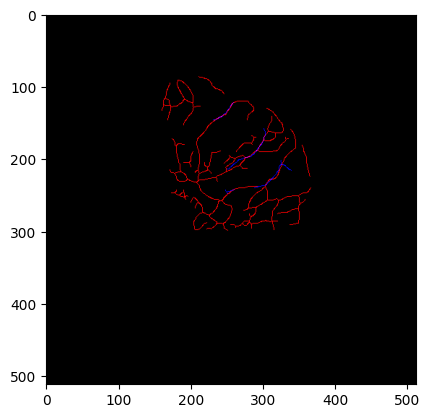

In [2]:
# #Process registration
# params.registration_type = "Skeleton"


error = main_Optics_to_MRI_registration(Mypath, params)
print(error)

error, display_img =  plot_registration_results(Mypath, params)
plt.figure()
plt.imshow(display_img)
plt.show()

# [TEMP] Plot registration results for all keypoints

18
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/18/Reg_params_custom_metric.json


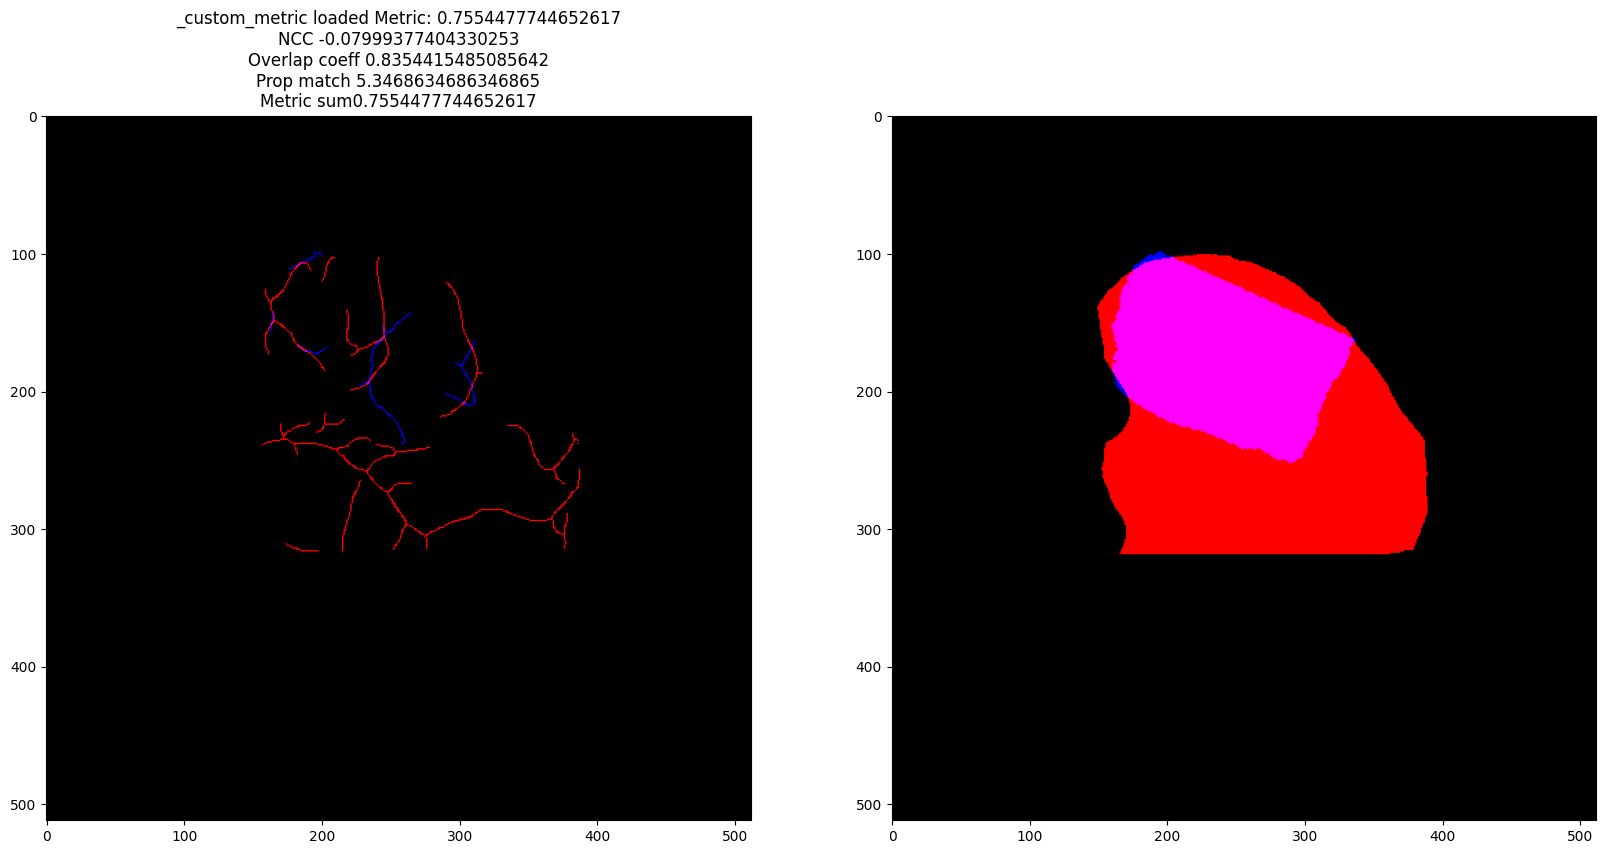

10
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/10/Reg_params_custom_metric.json


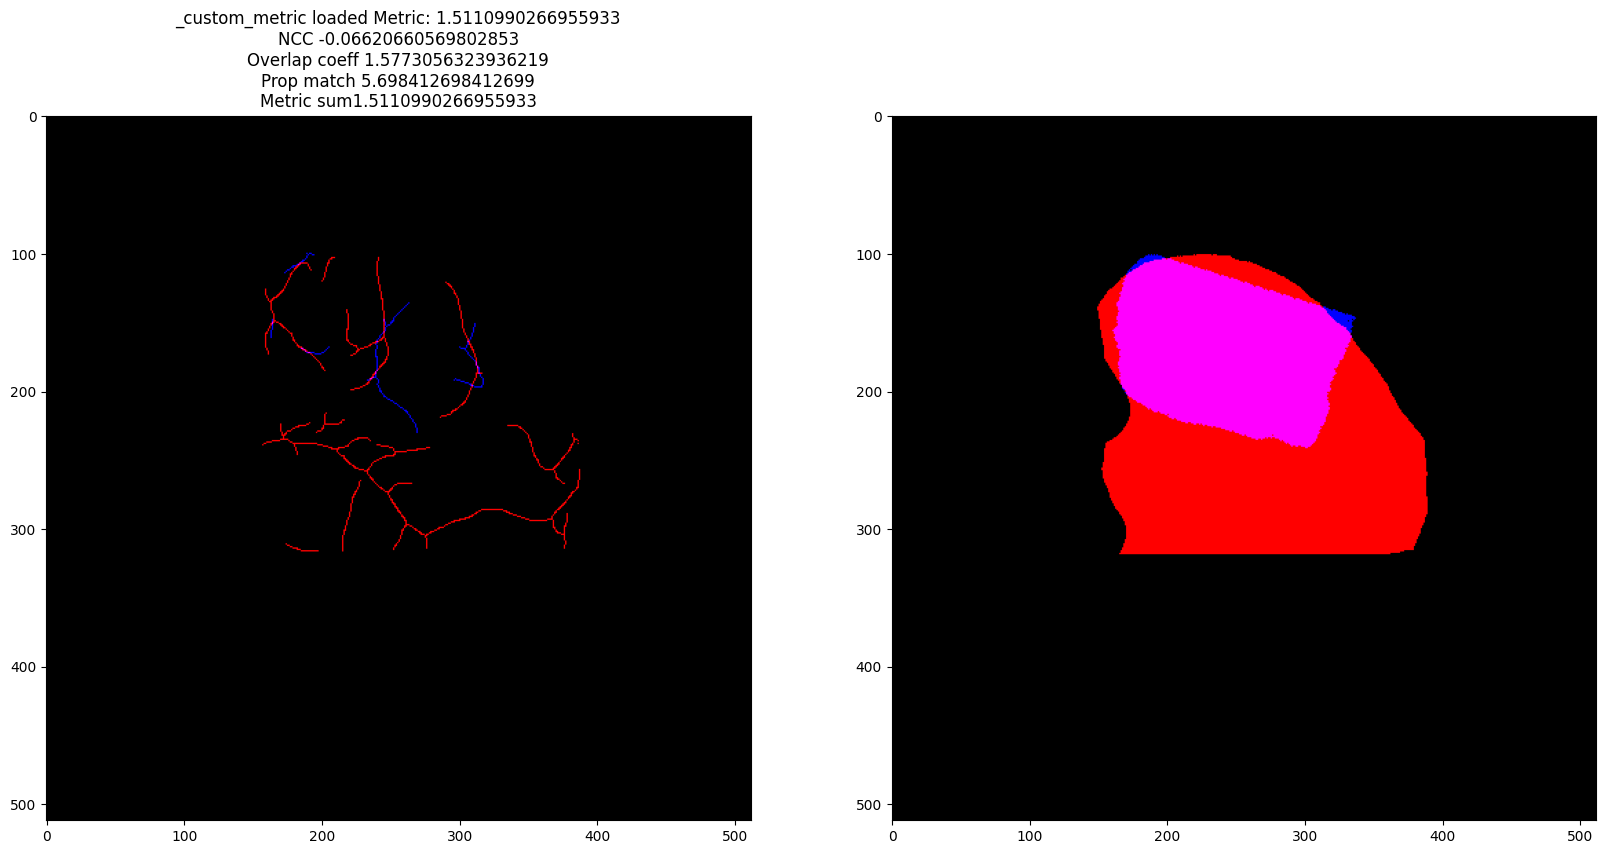

14
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/14/Reg_params_custom_metric.json


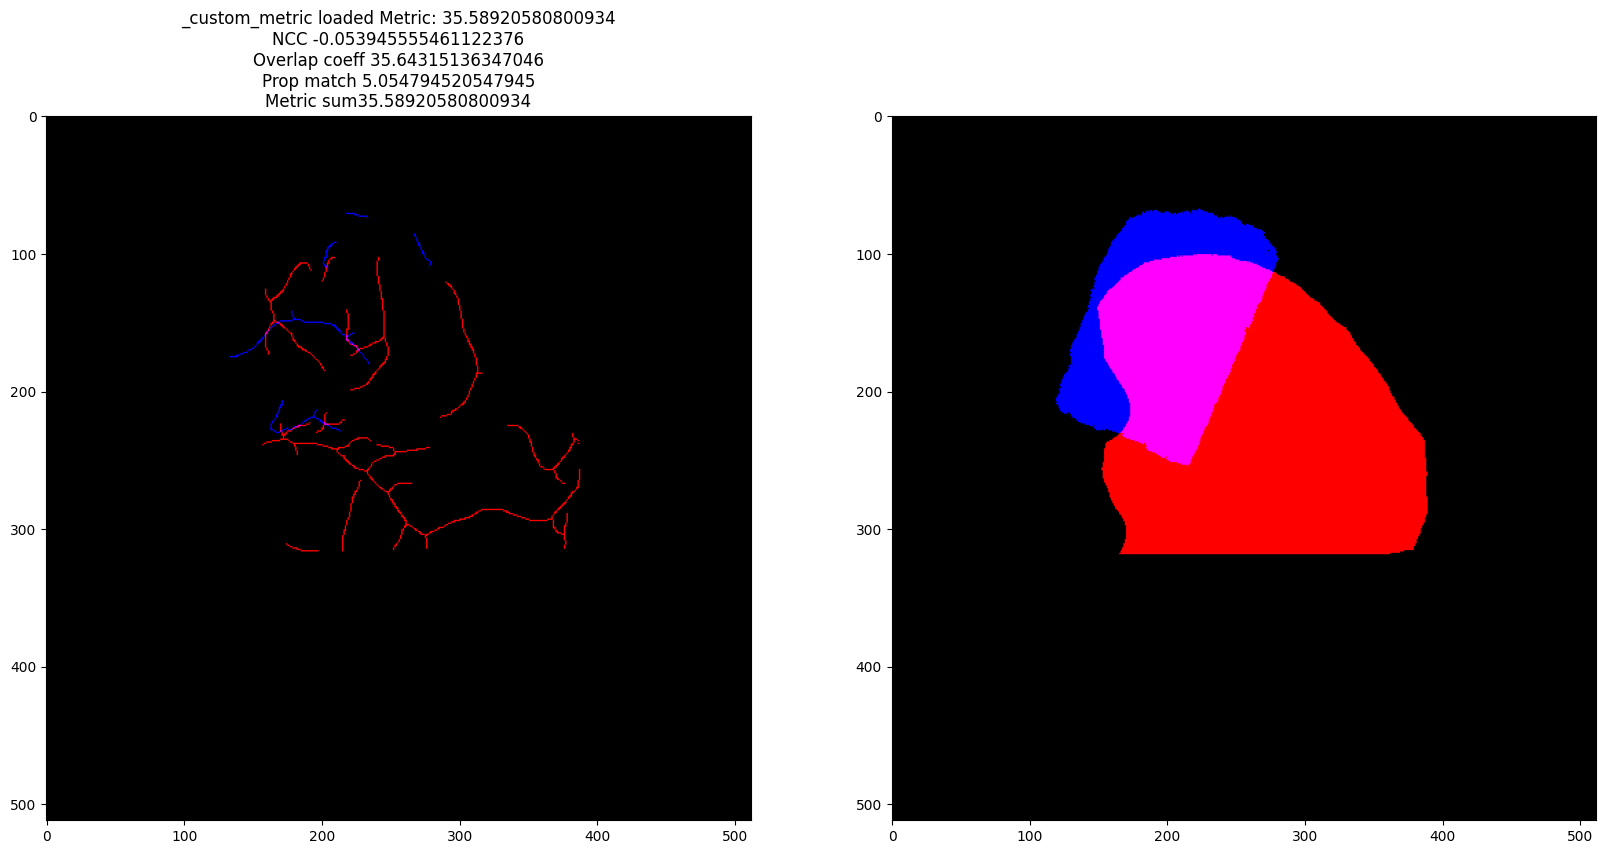

24
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/24/Reg_params_custom_metric.json


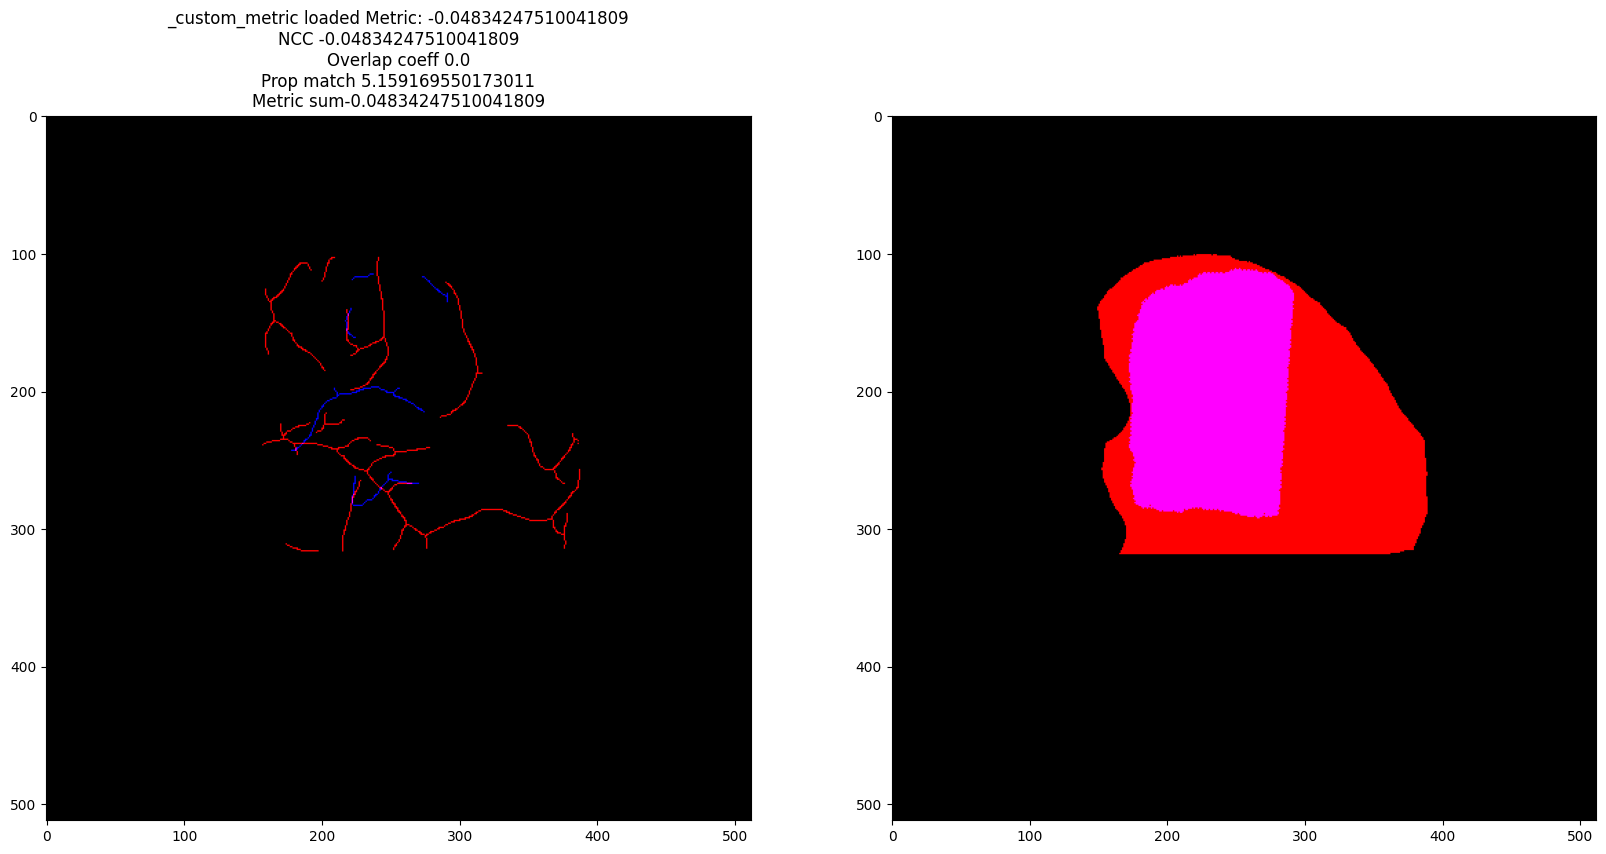

12
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/12/Reg_params_custom_metric.json


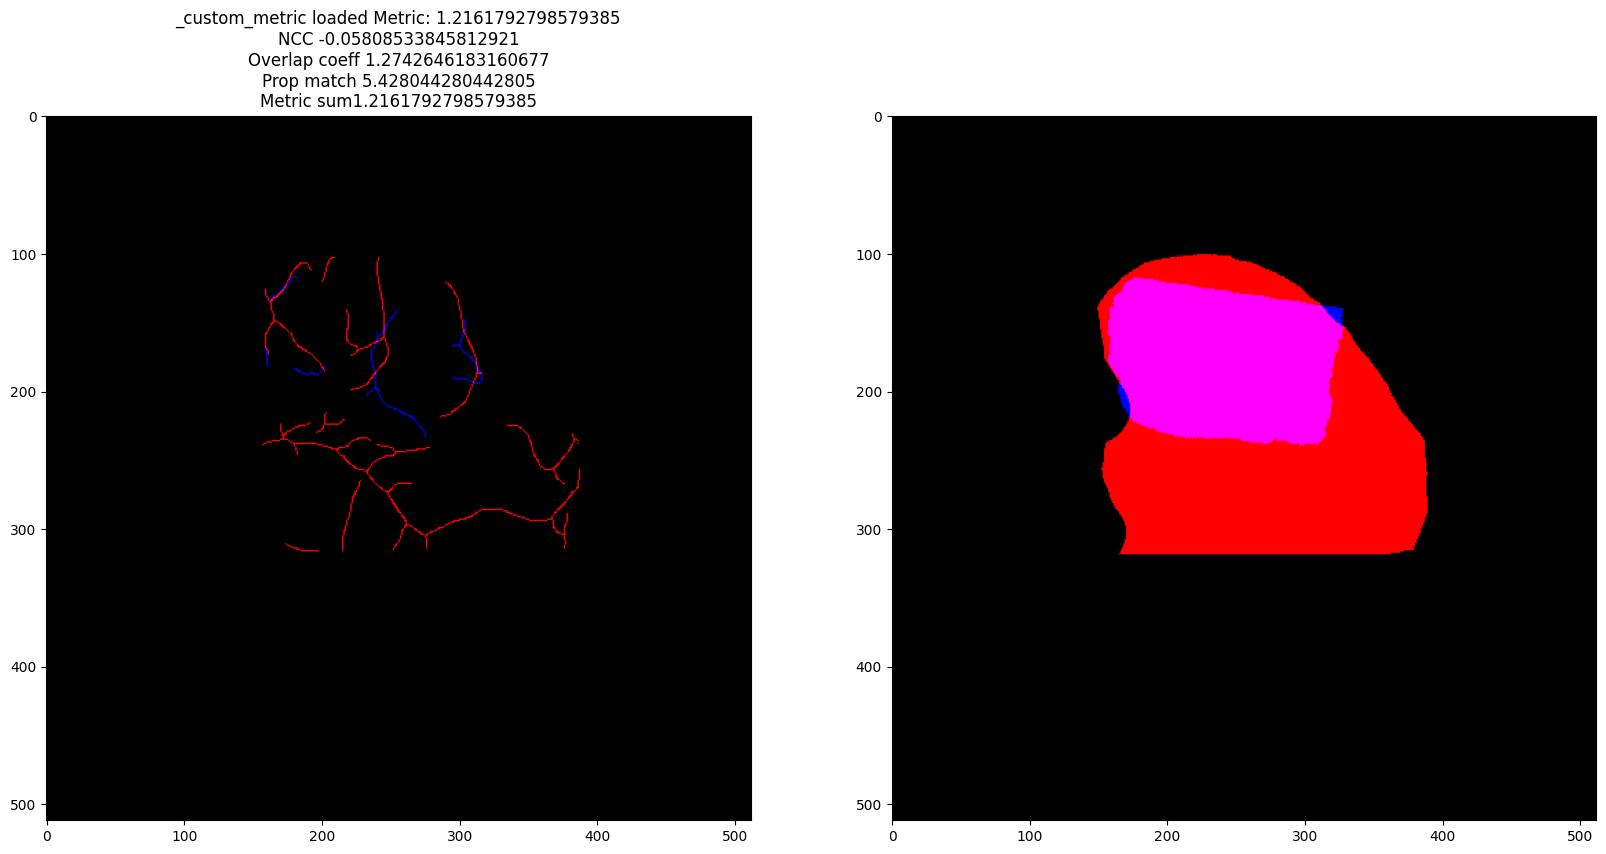

25
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/25/Reg_params_custom_metric.json


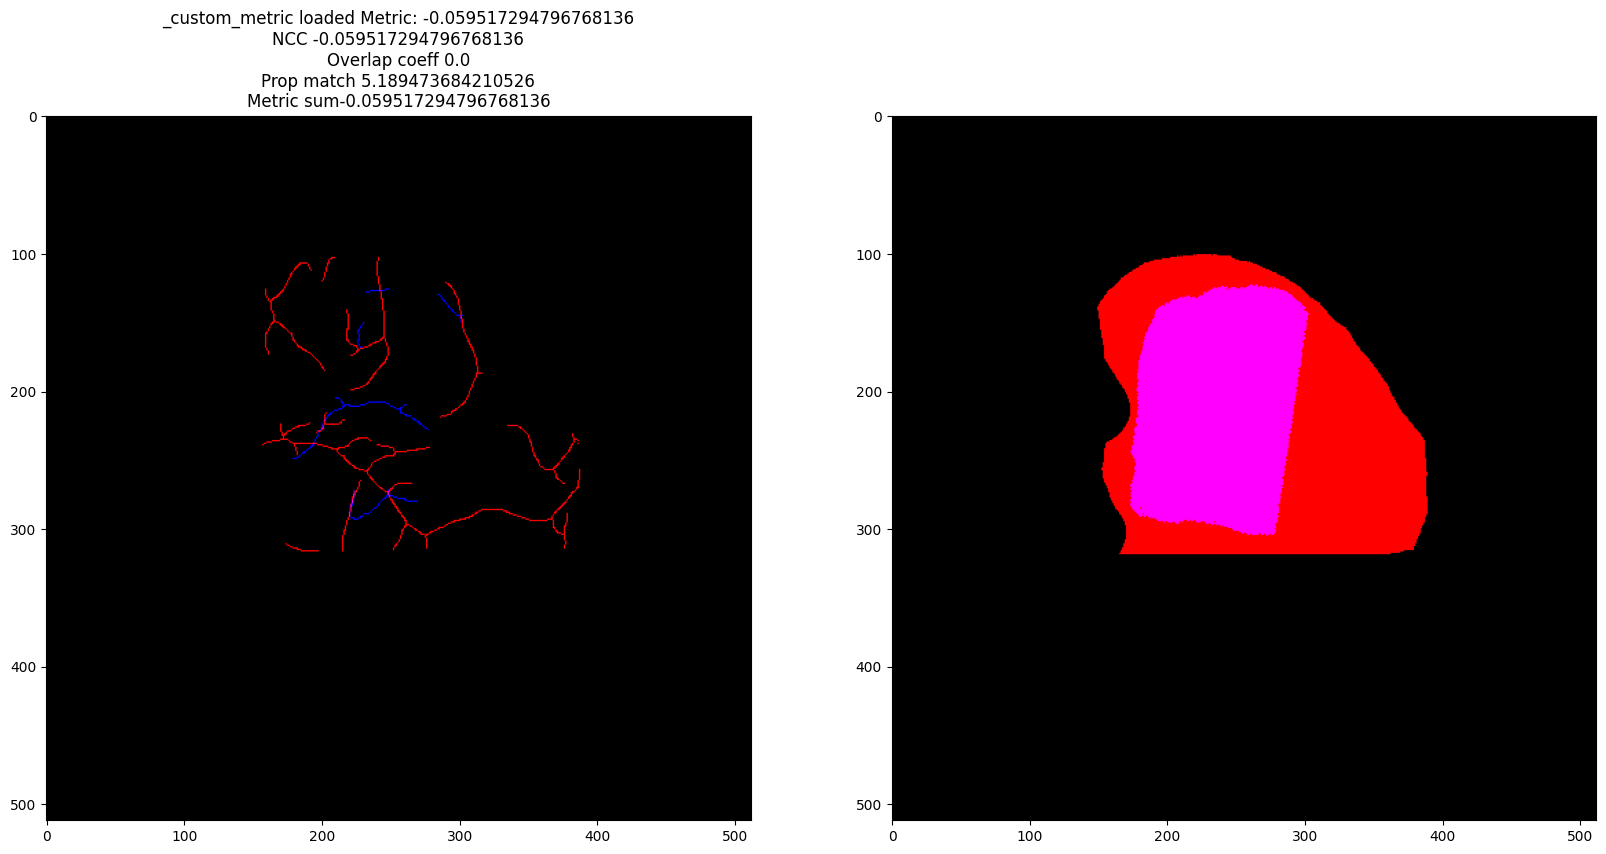

11
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/11/Reg_params_custom_metric.json


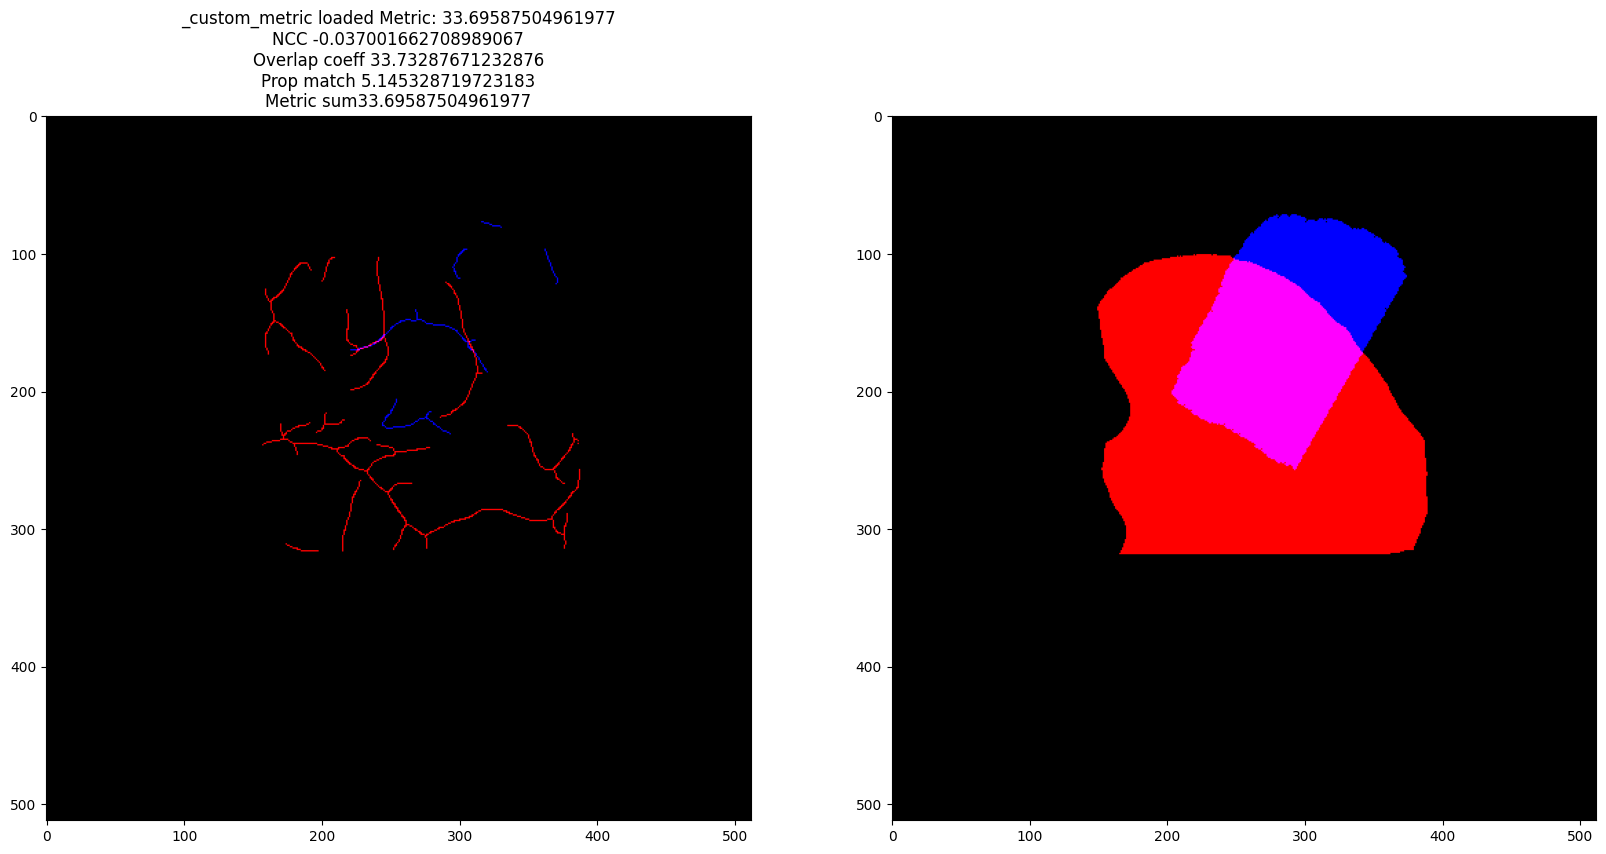

17
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/17/Reg_params_custom_metric.json


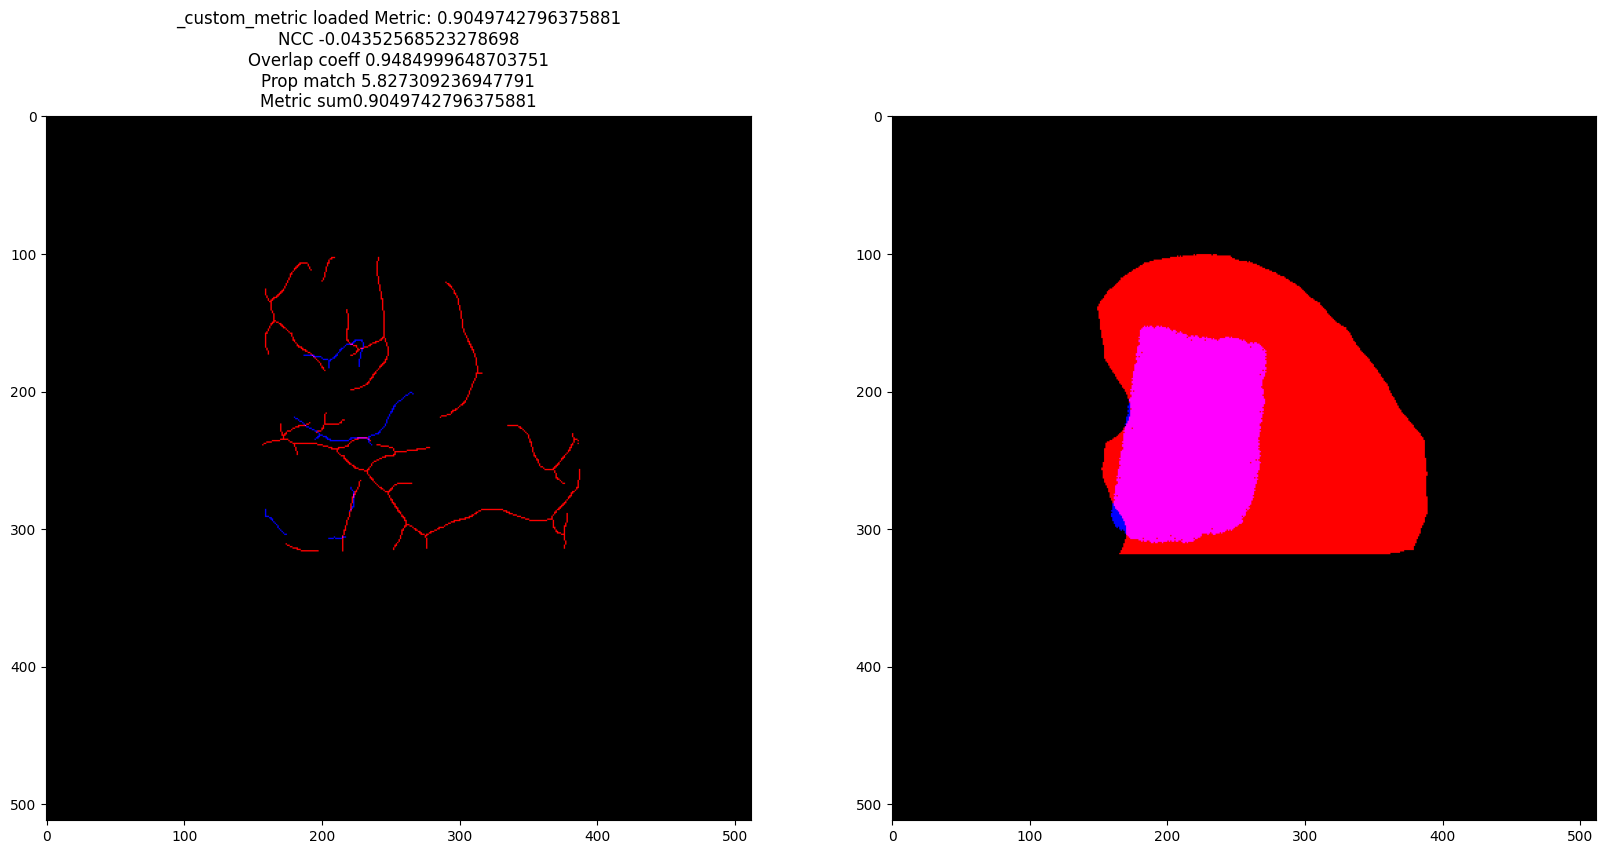

22
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/22/Reg_params_custom_metric.json


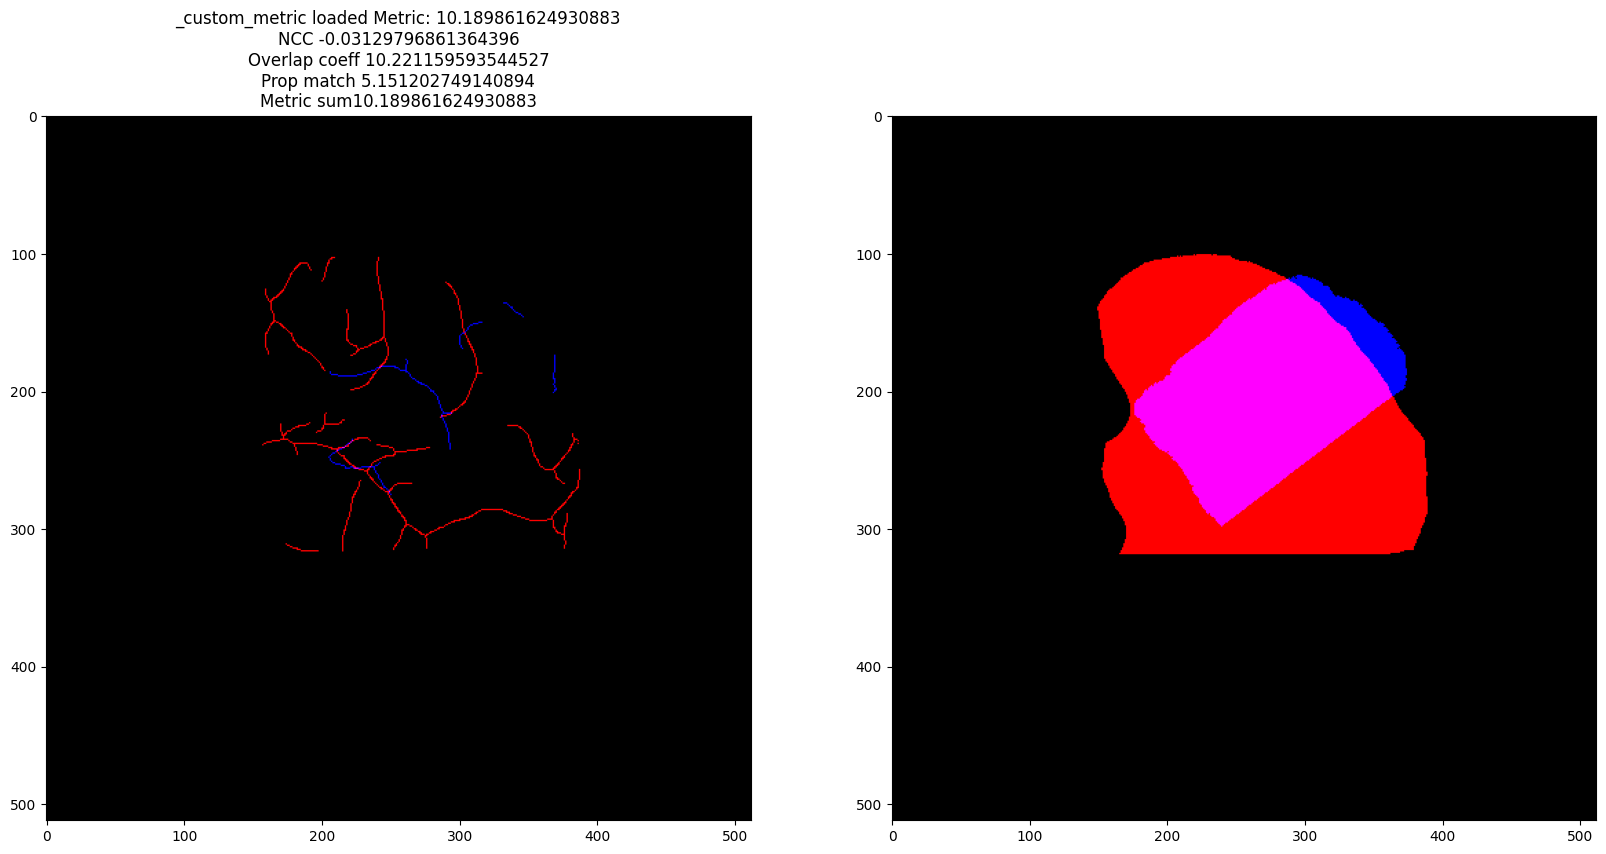

16
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/16/Reg_params_custom_metric.json


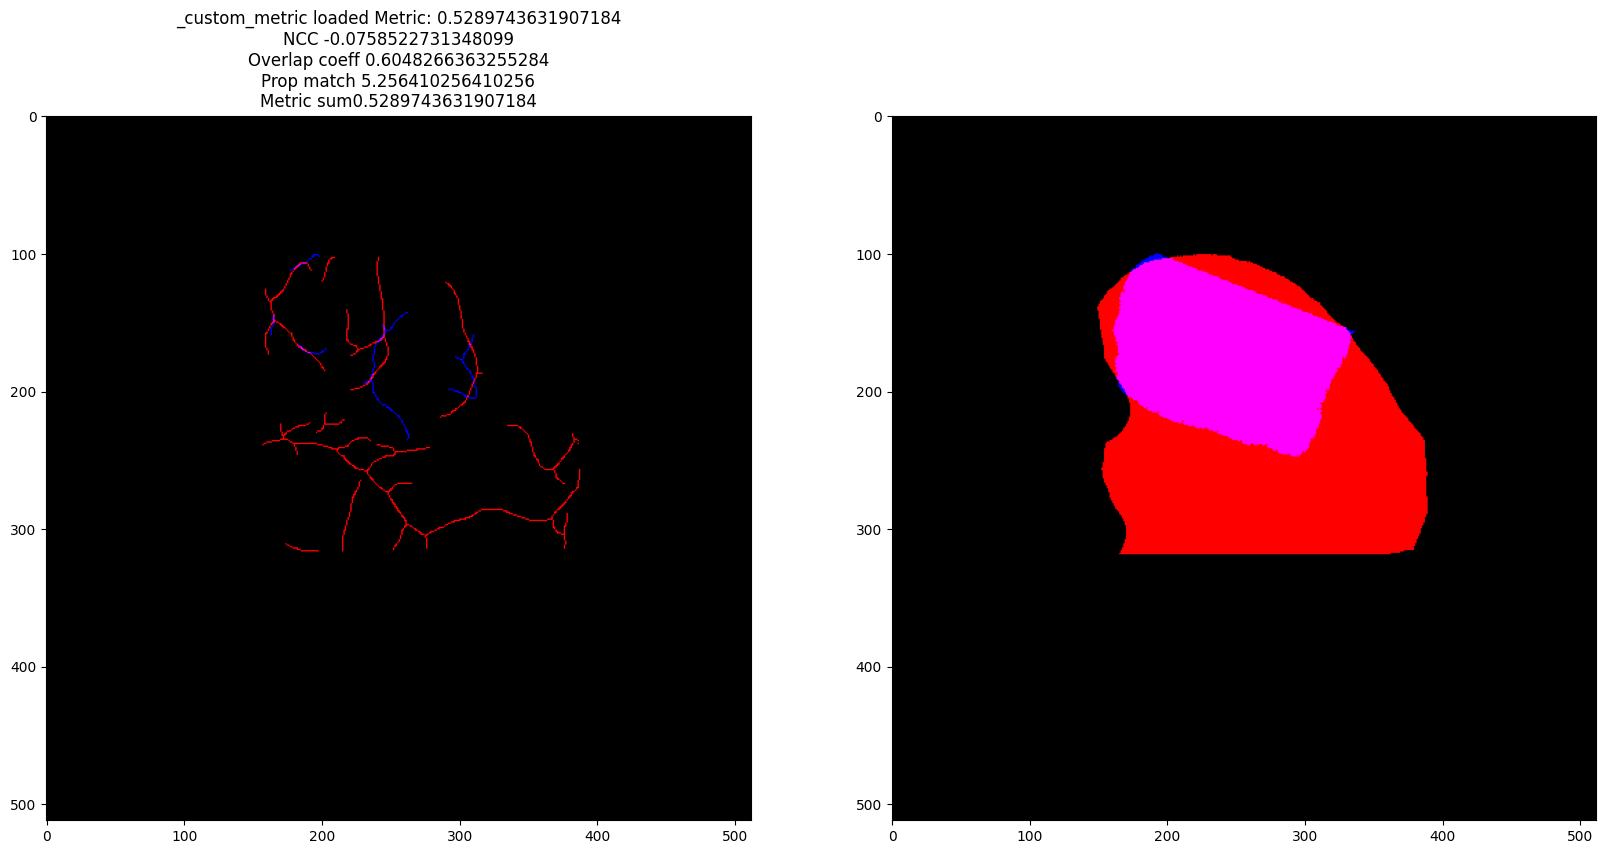

27
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/27/Reg_params_custom_metric.json


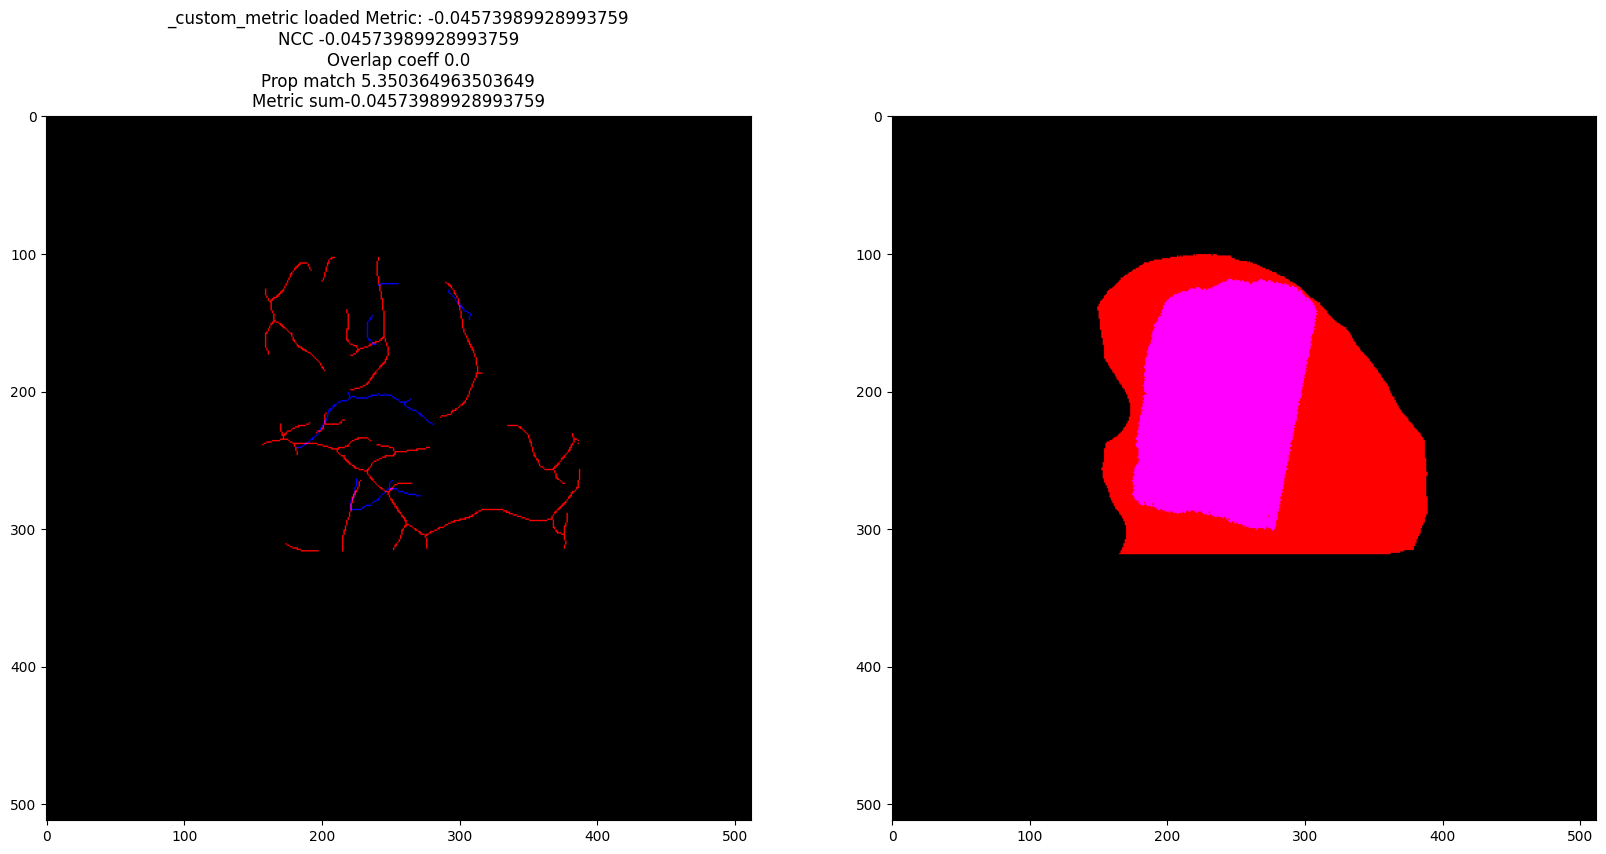

7
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/7/Reg_params_custom_metric.json


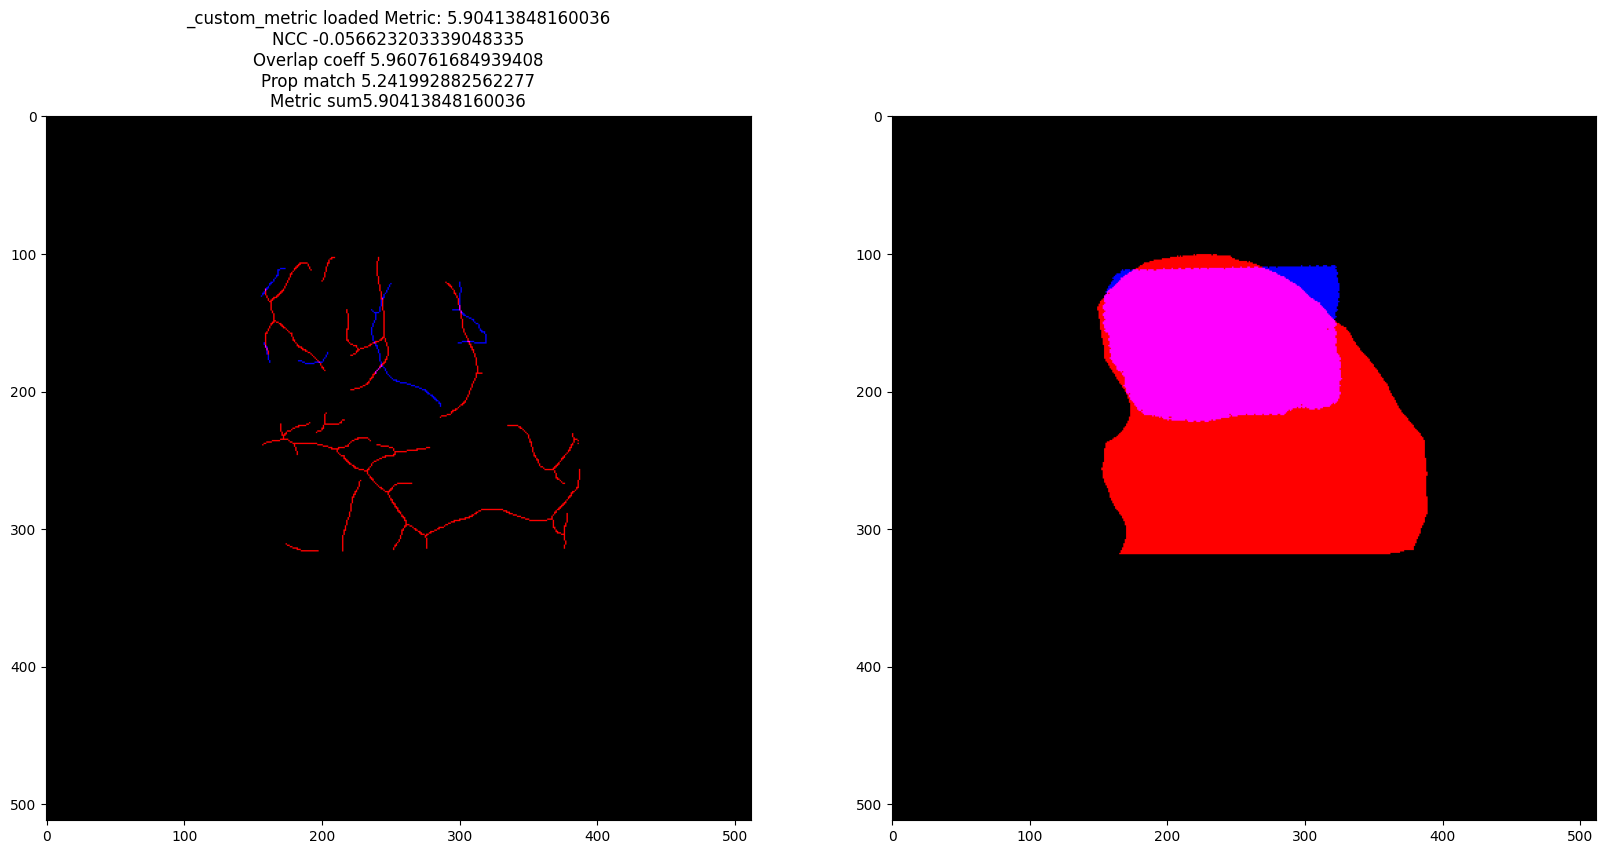

8
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/8/Reg_params_custom_metric.json


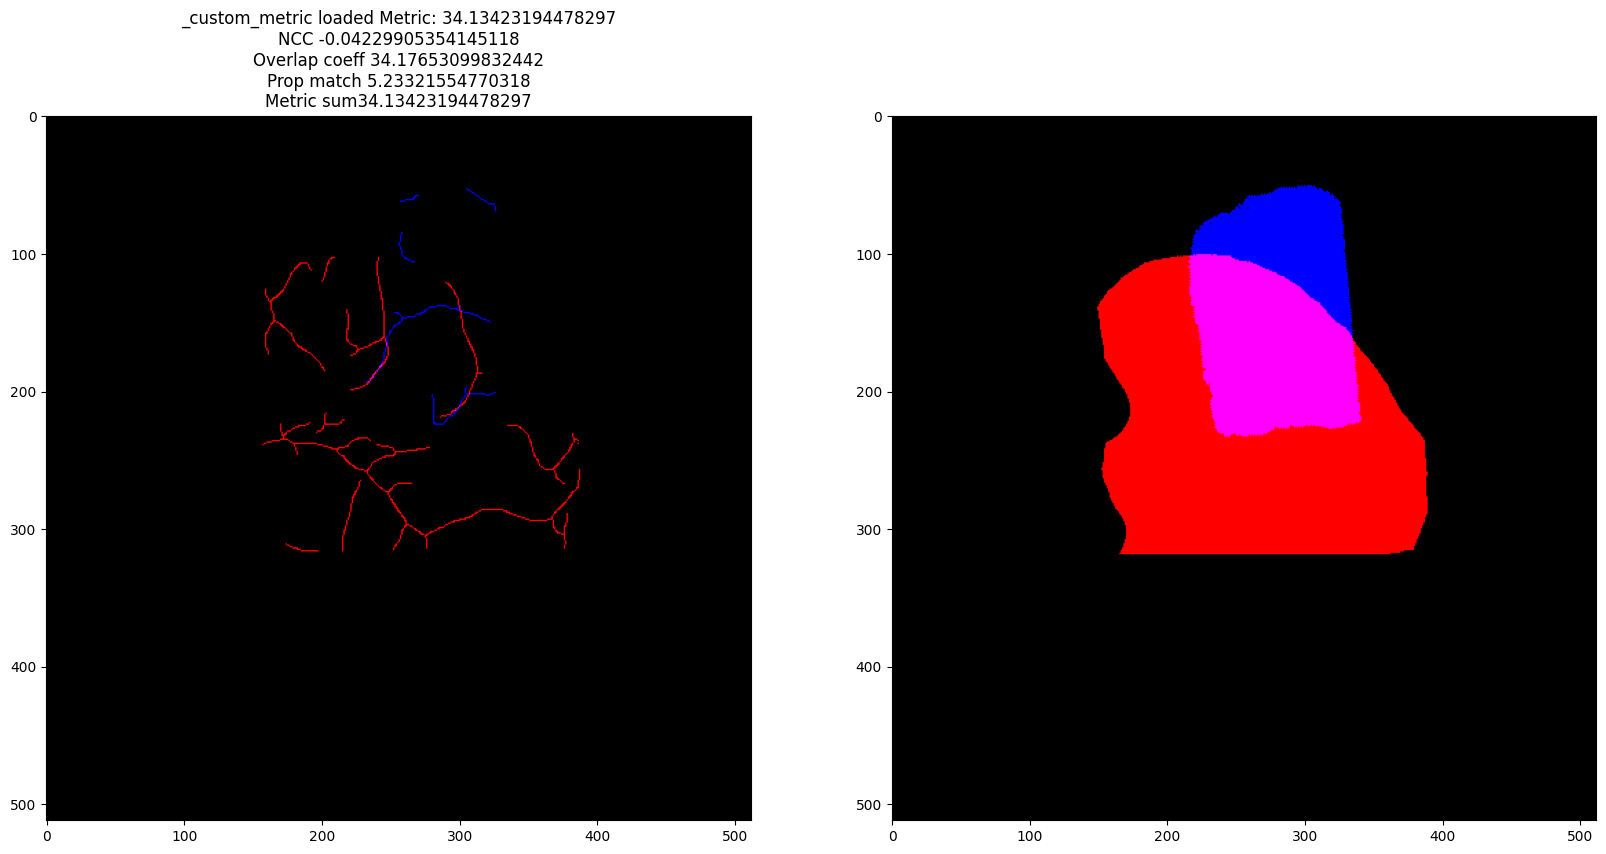

19
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/19/Reg_params_custom_metric.json


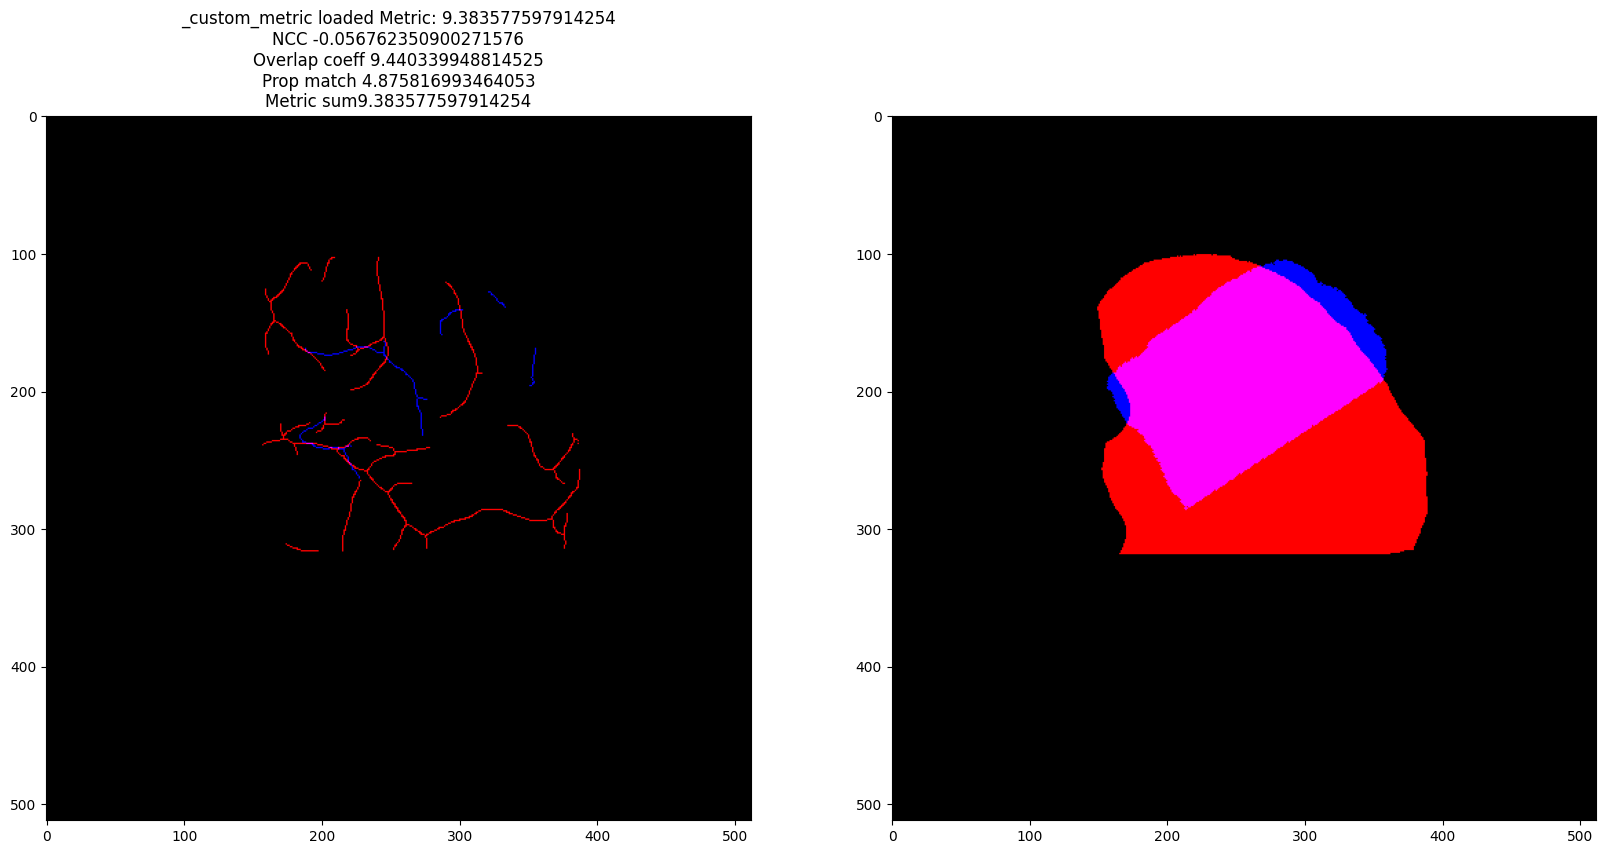

26
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/26/Reg_params_custom_metric.json


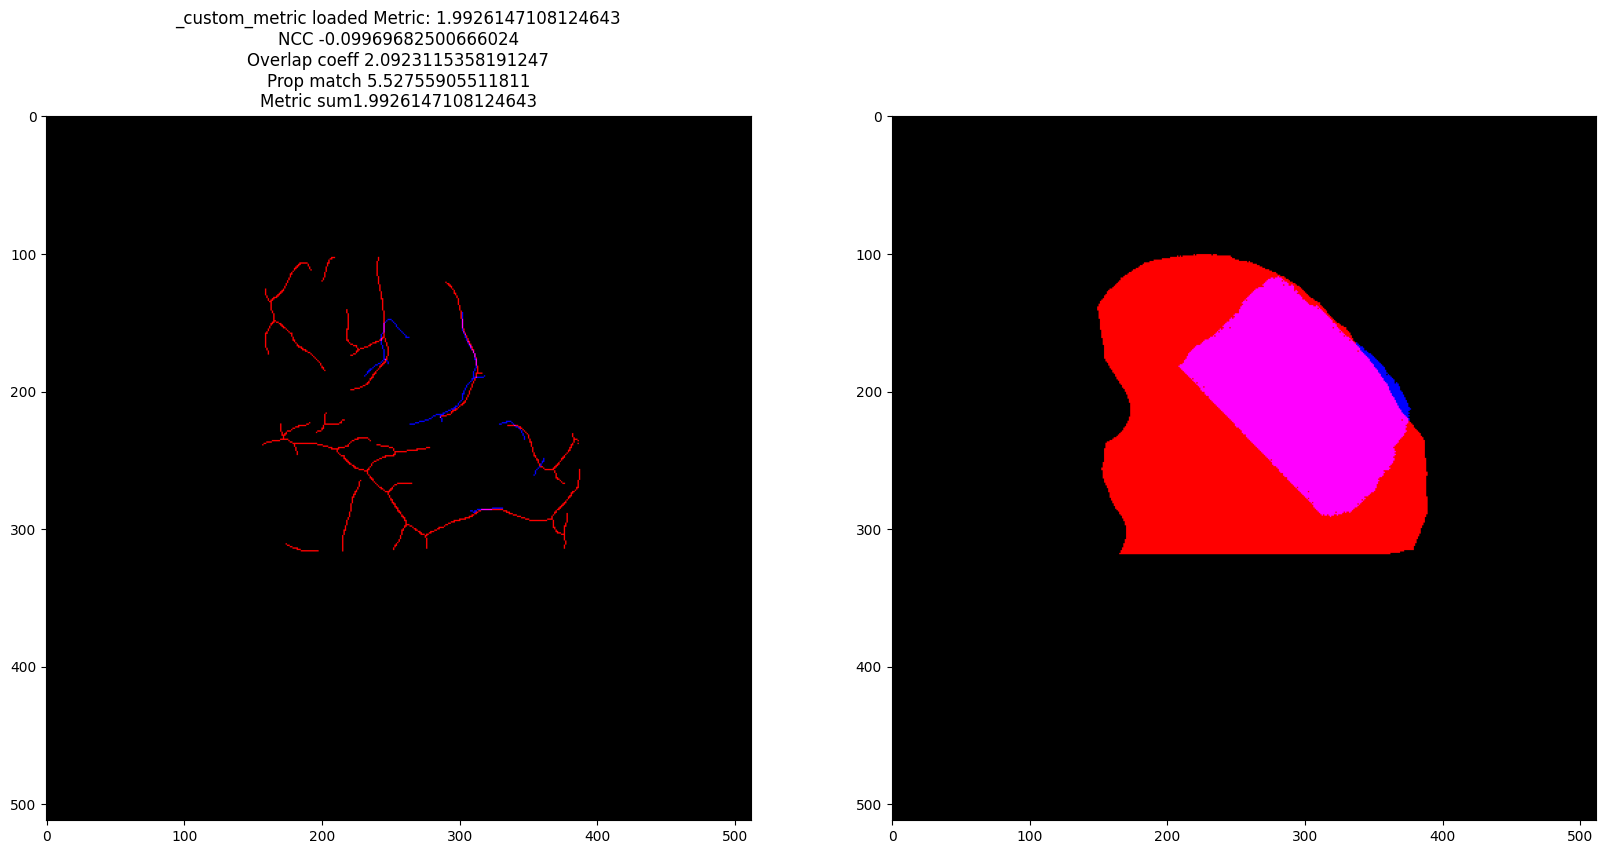

15
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/15/Reg_params_custom_metric.json


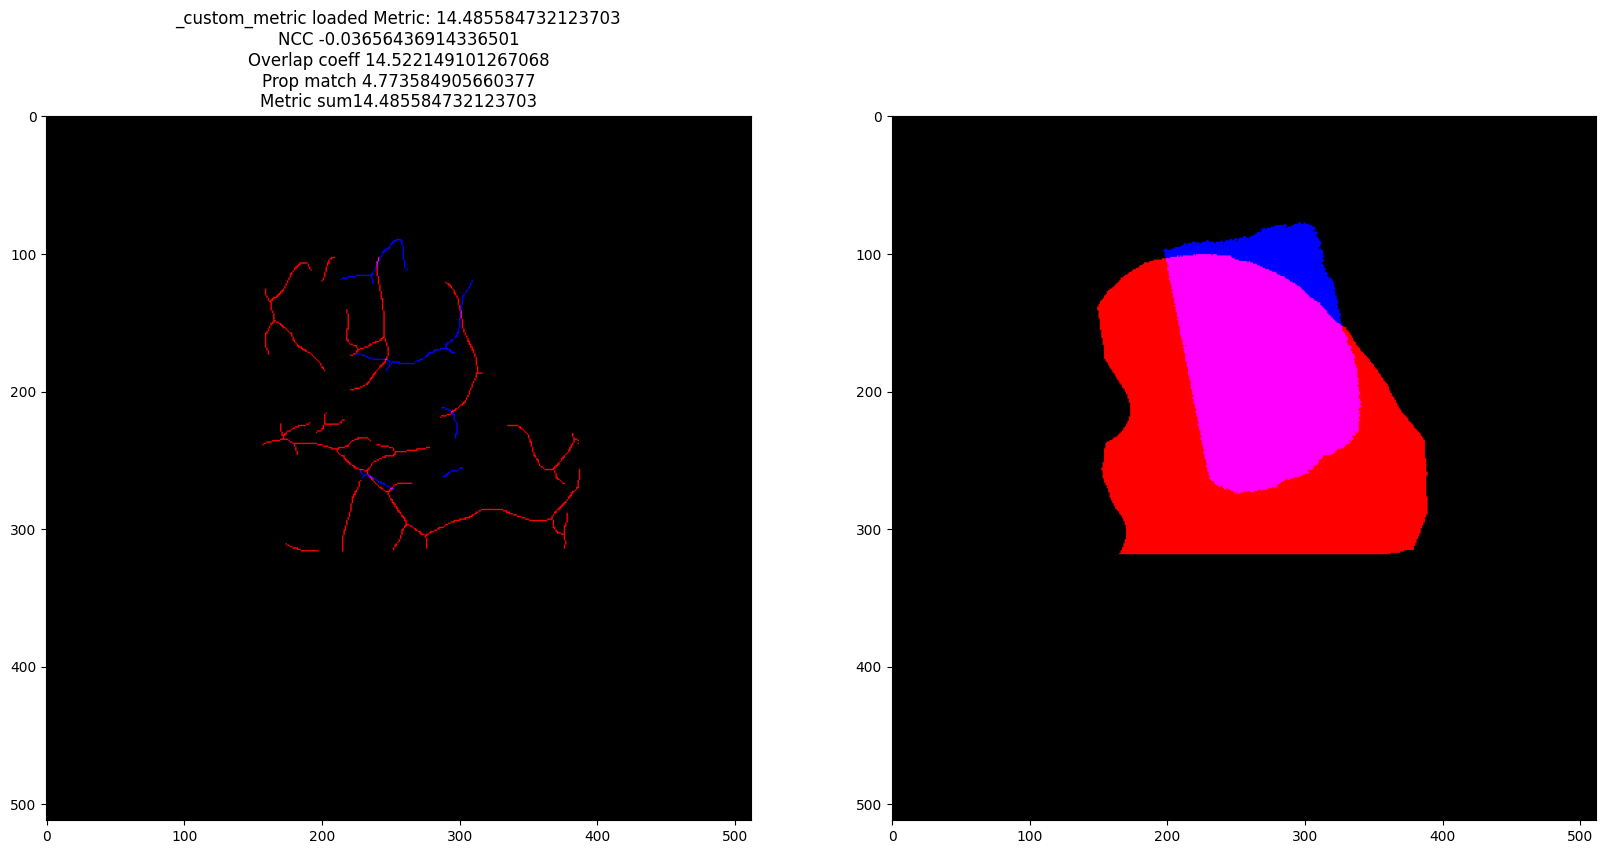

1
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/1/Reg_params_custom_metric.json


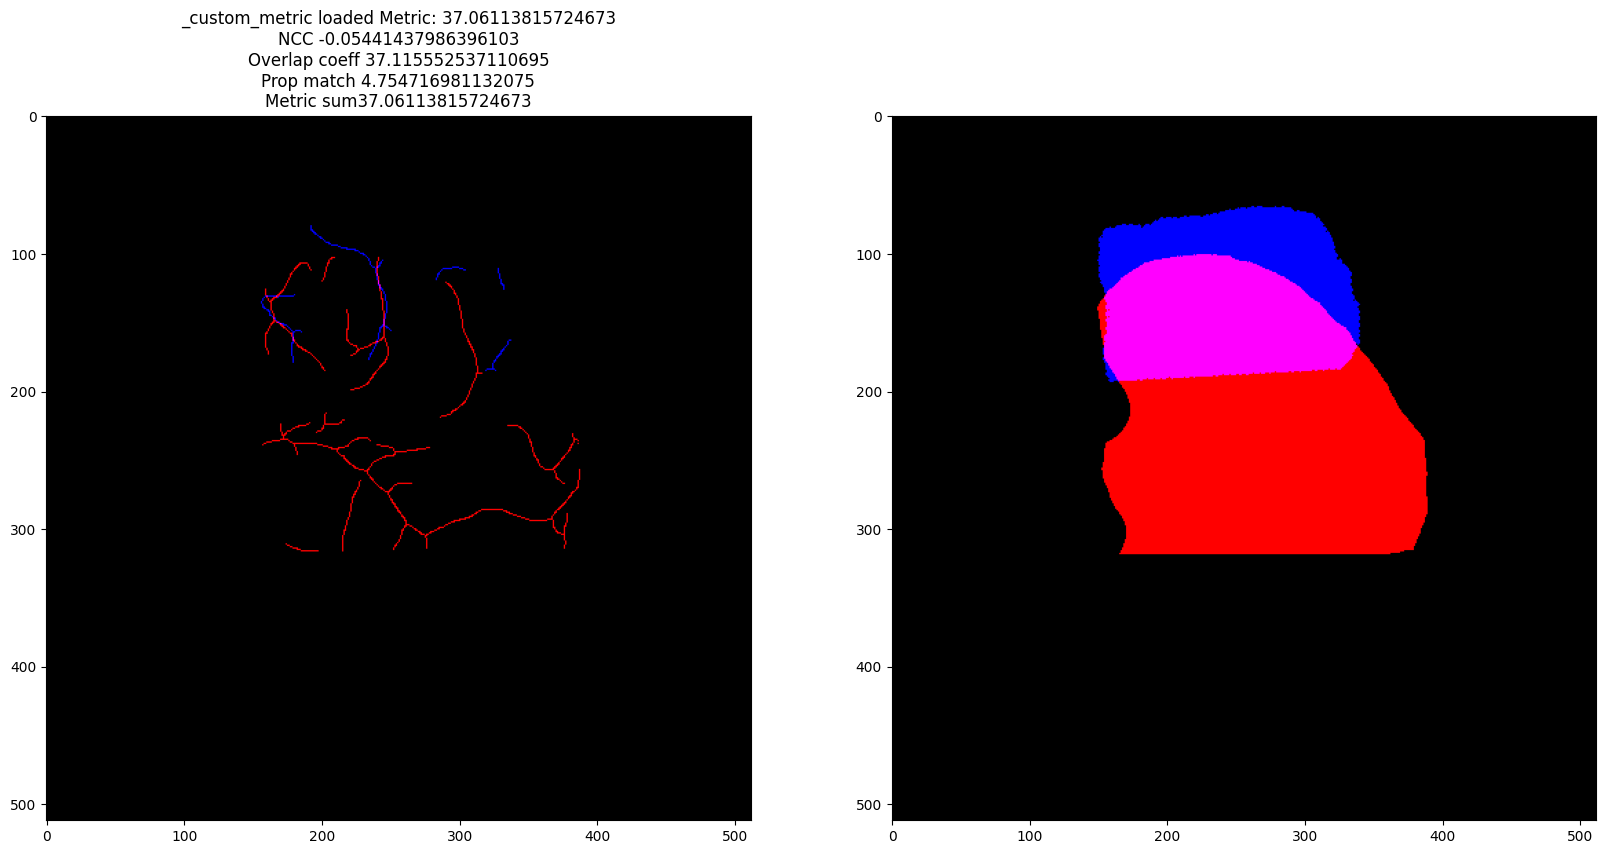

5
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/5/Reg_params_custom_metric.json


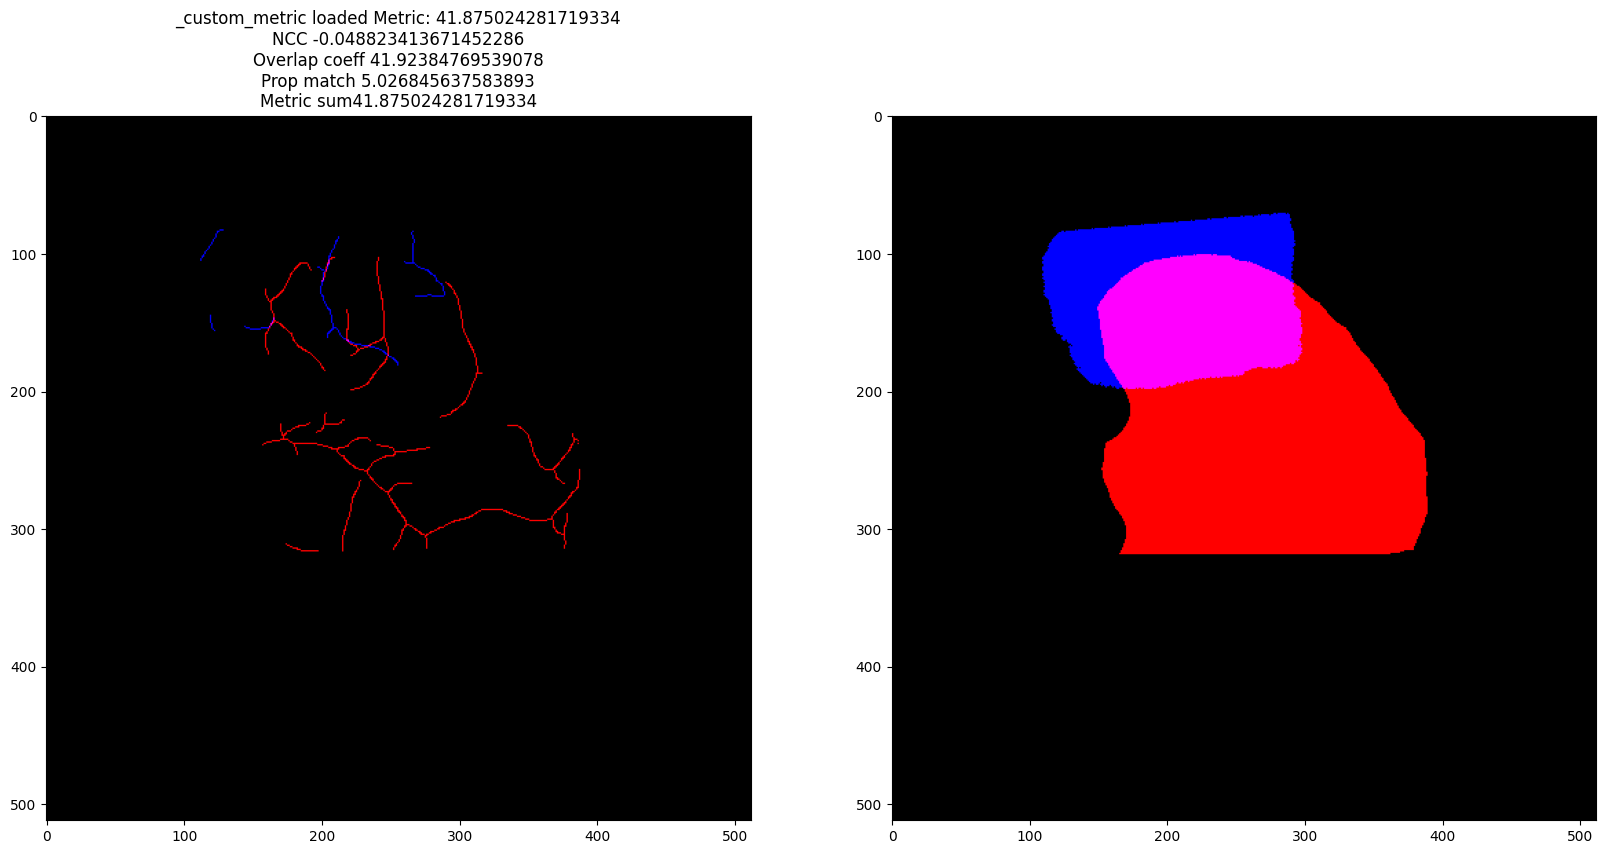

6
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/6/Reg_params_custom_metric.json


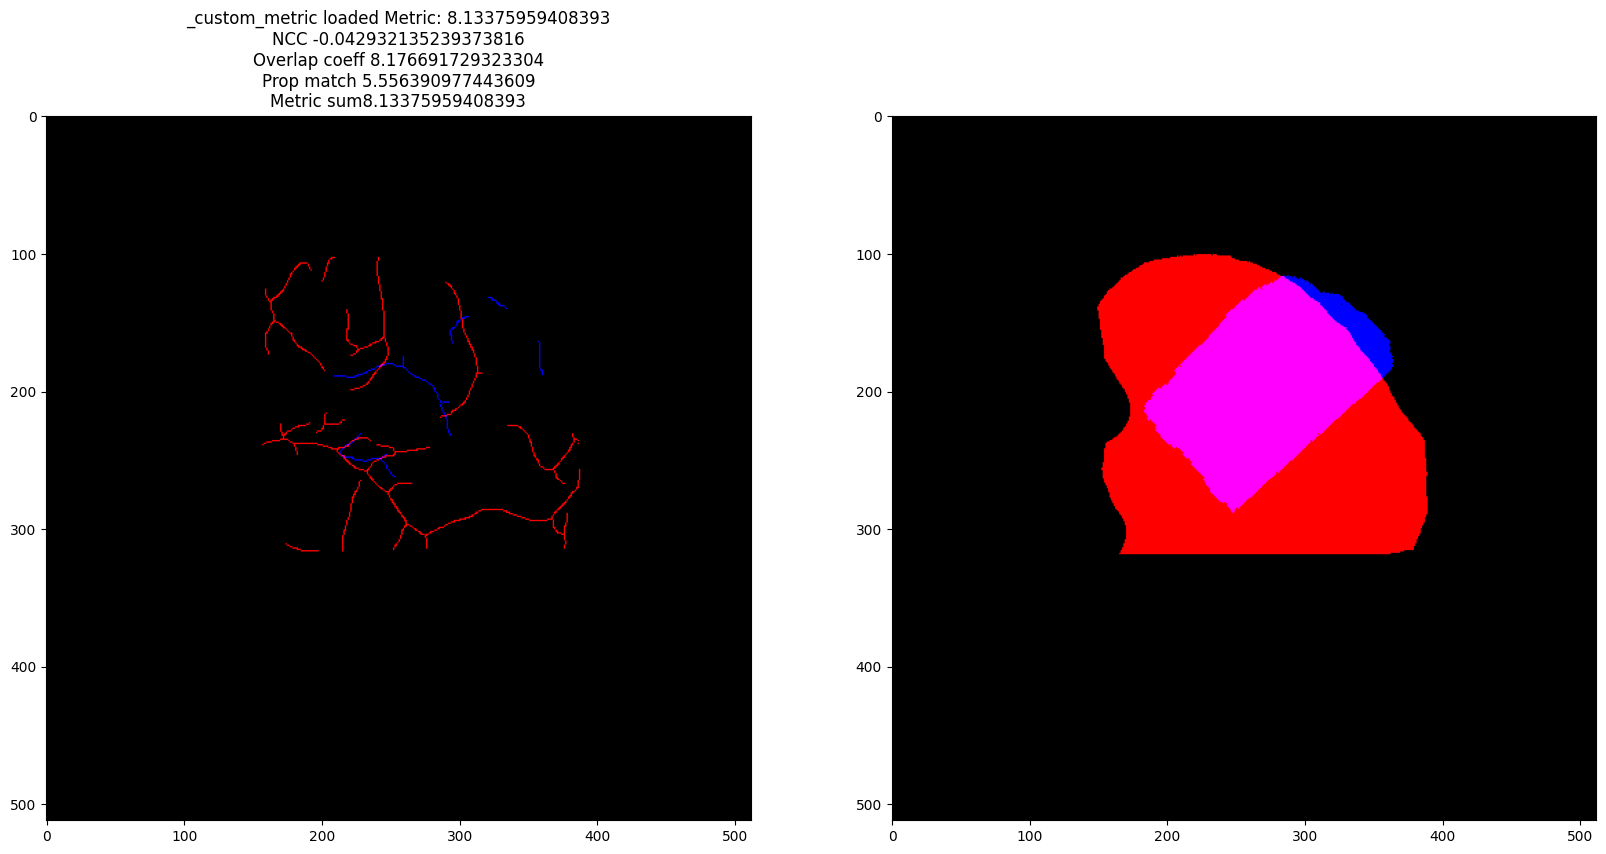

2
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/2/Reg_params_custom_metric.json


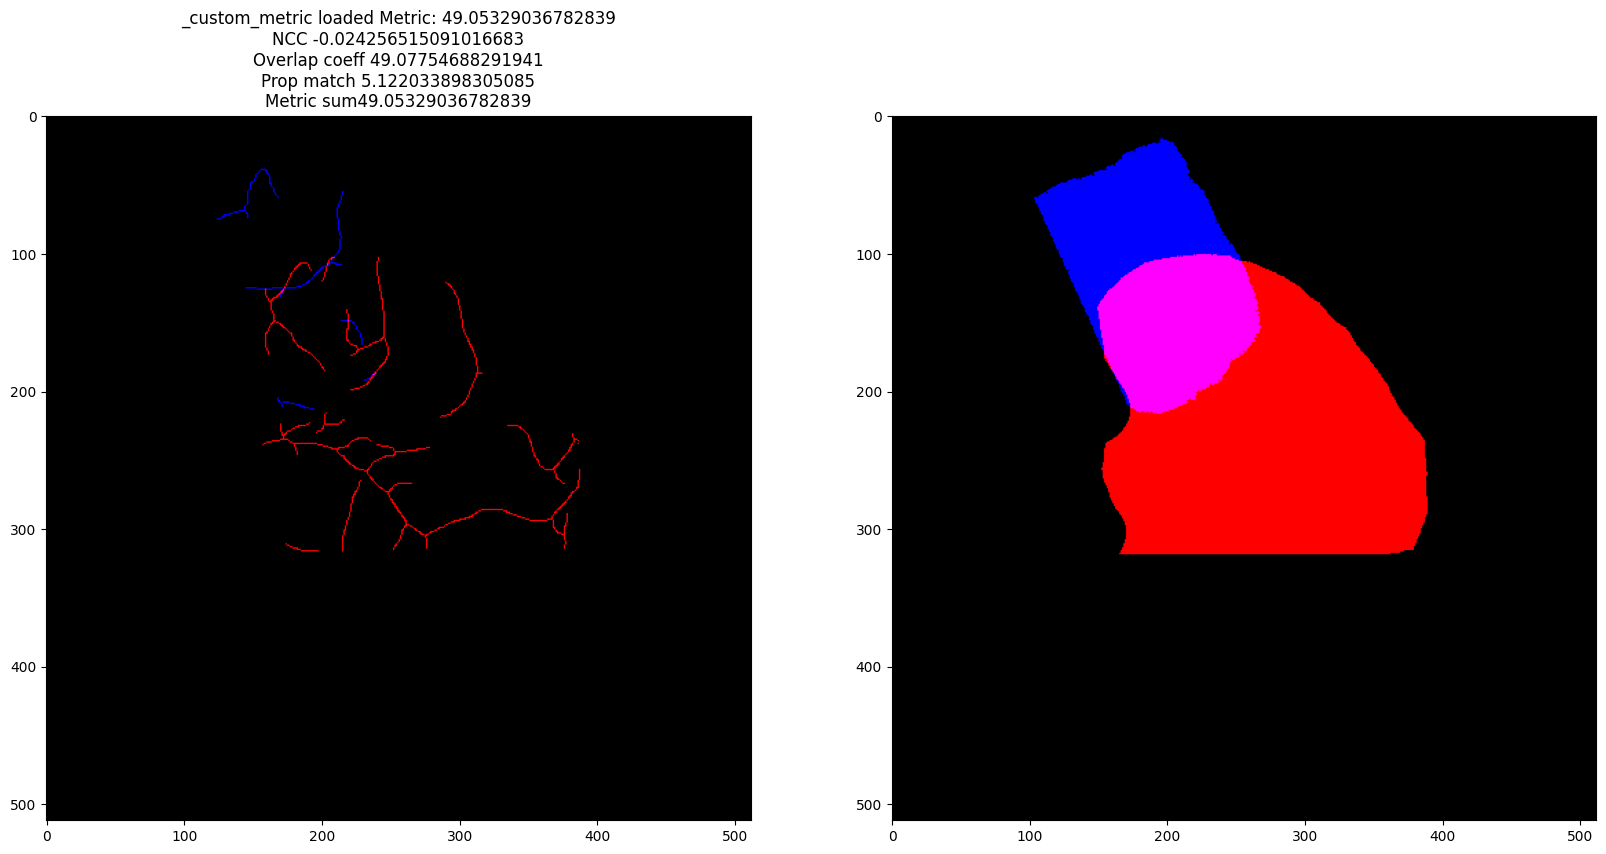

20
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/20/Reg_params_custom_metric.json


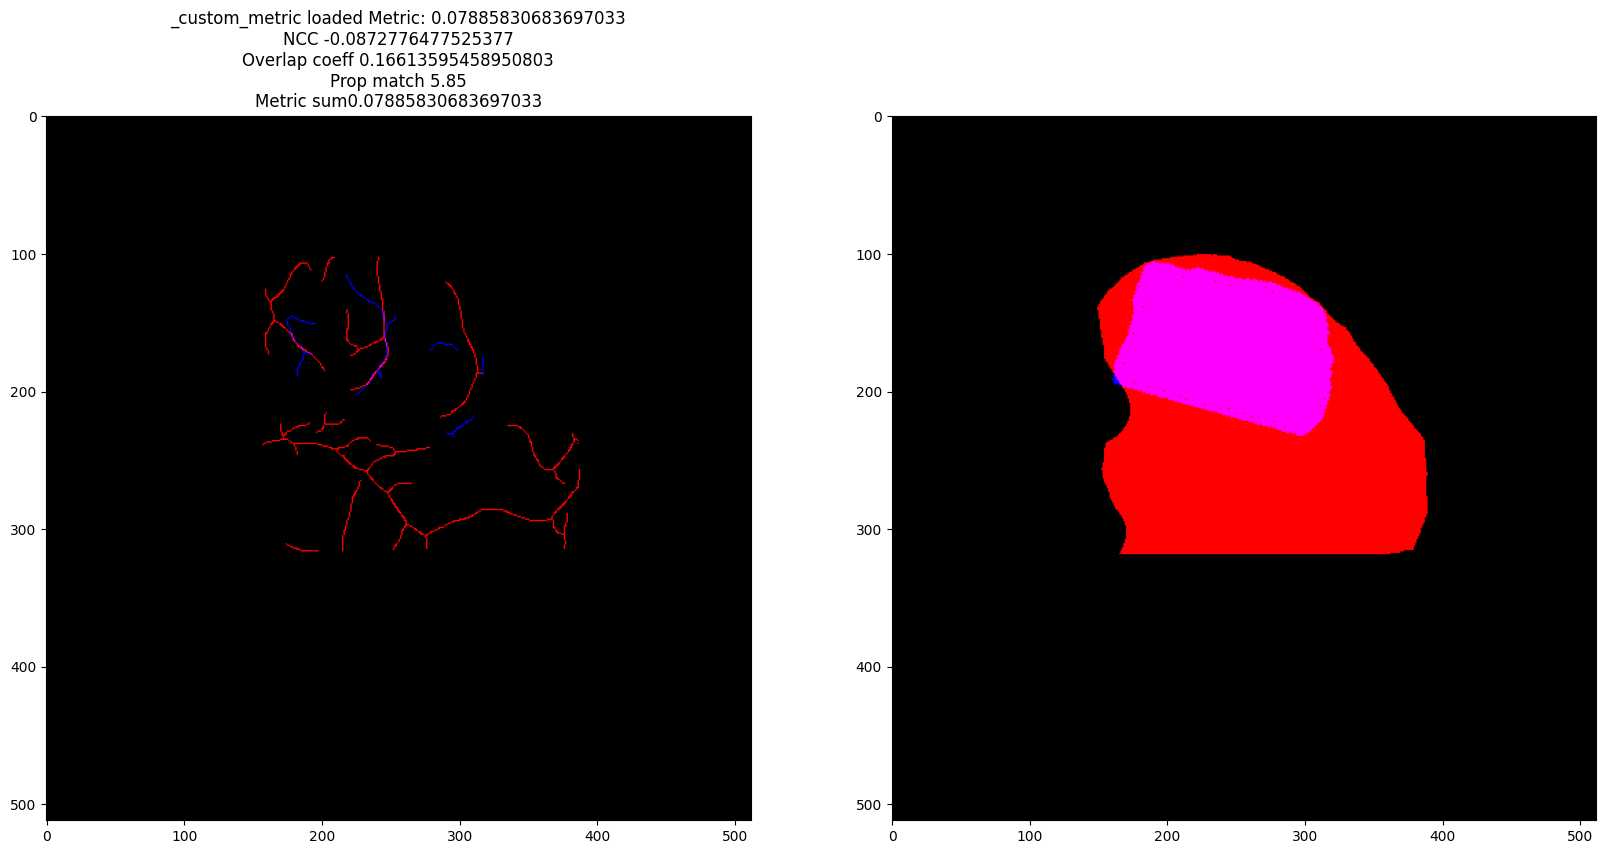

0
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/0/Reg_params_custom_metric.json


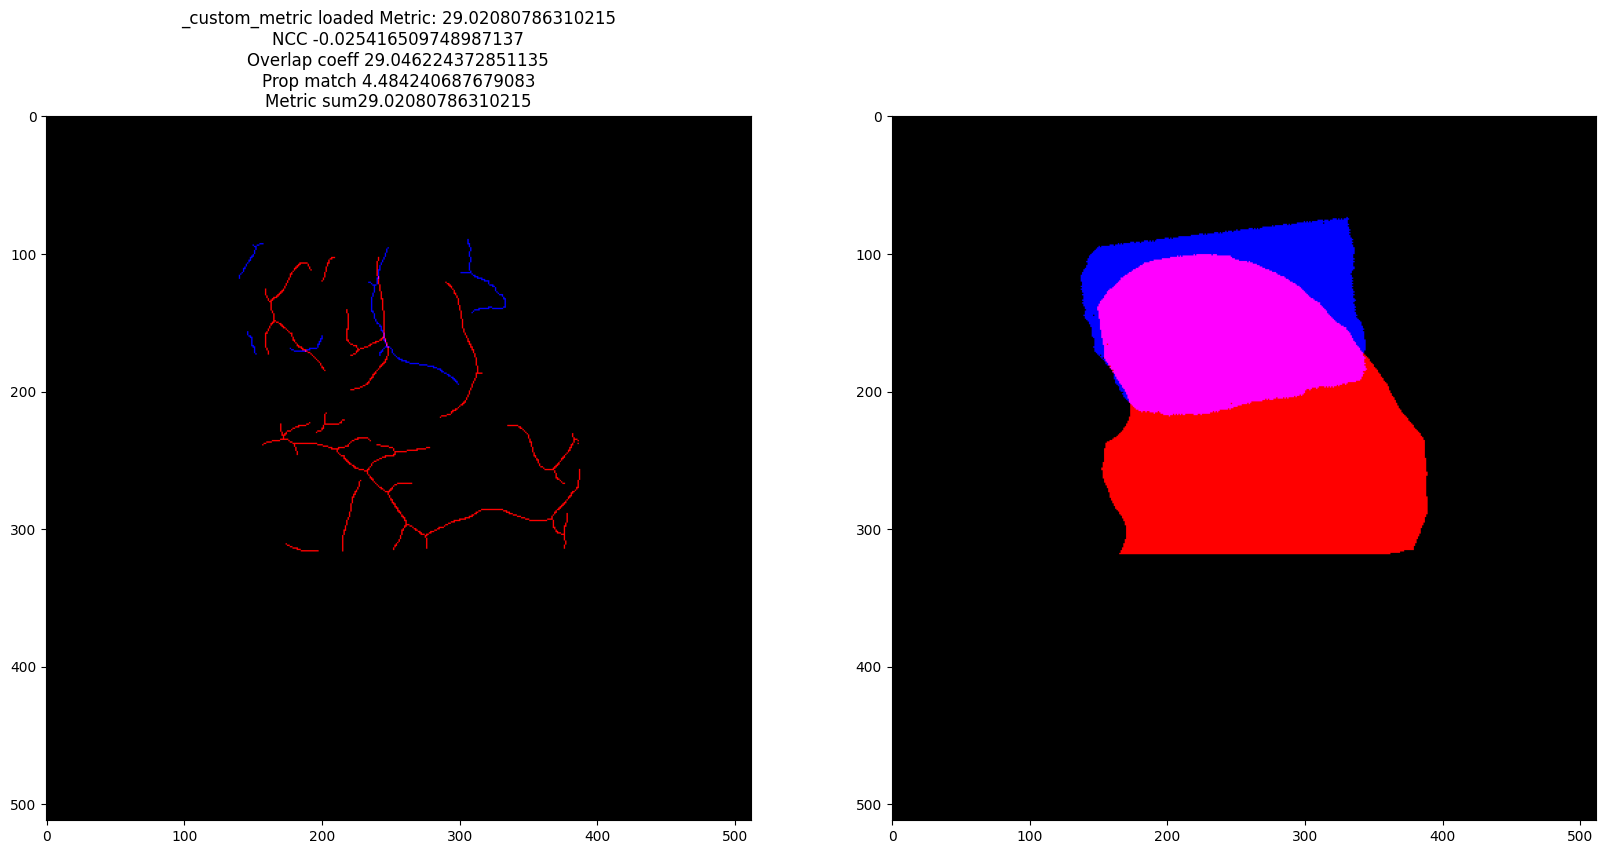

21
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/21/Reg_params_custom_metric.json


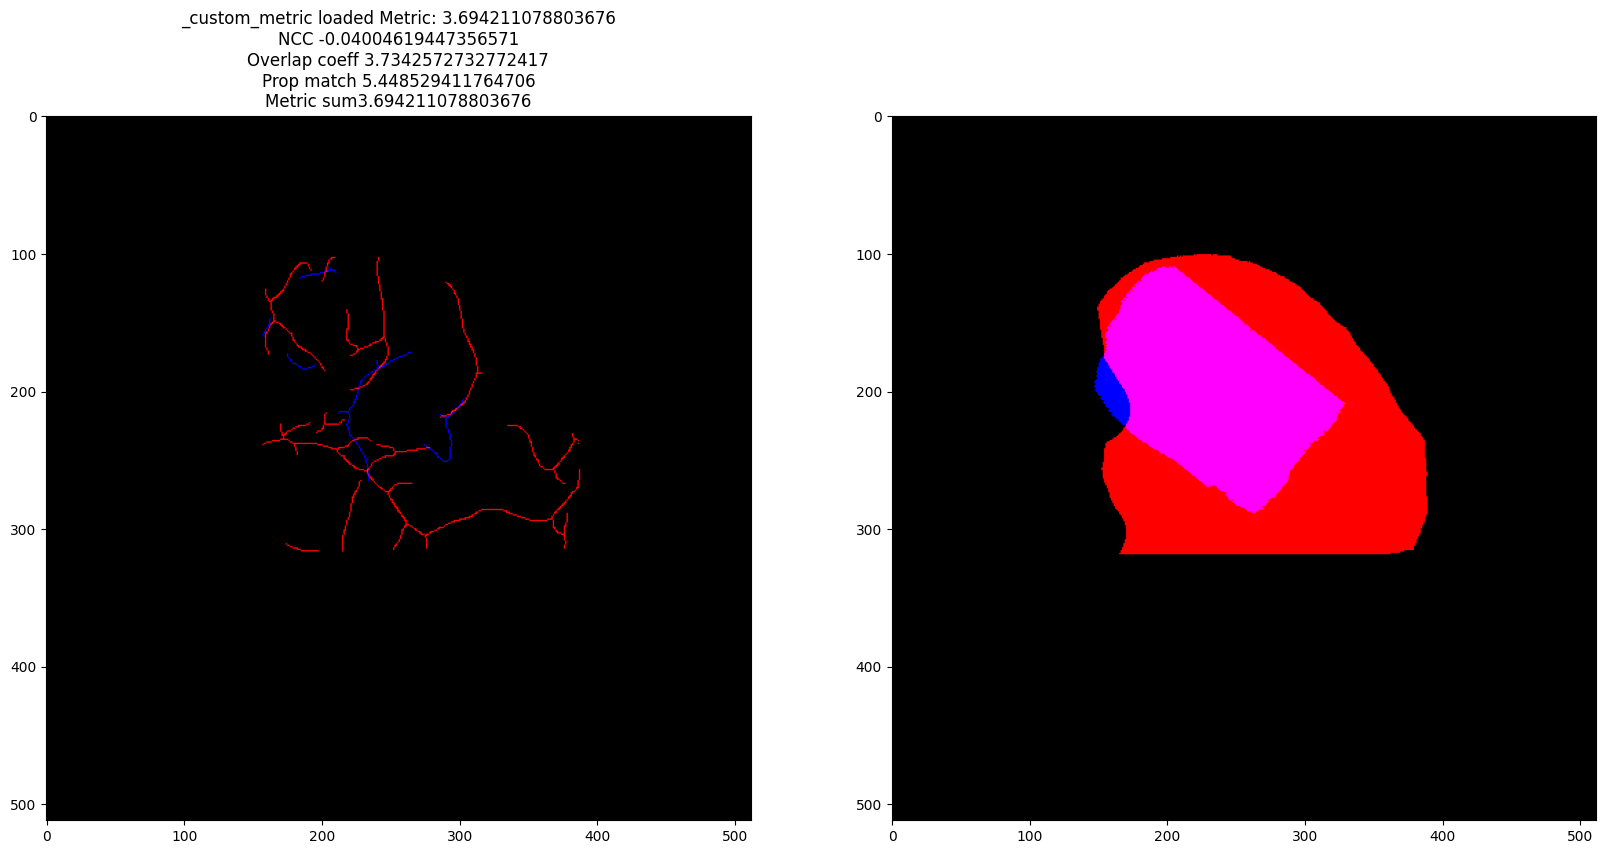

28
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/28/Reg_params_custom_metric.json


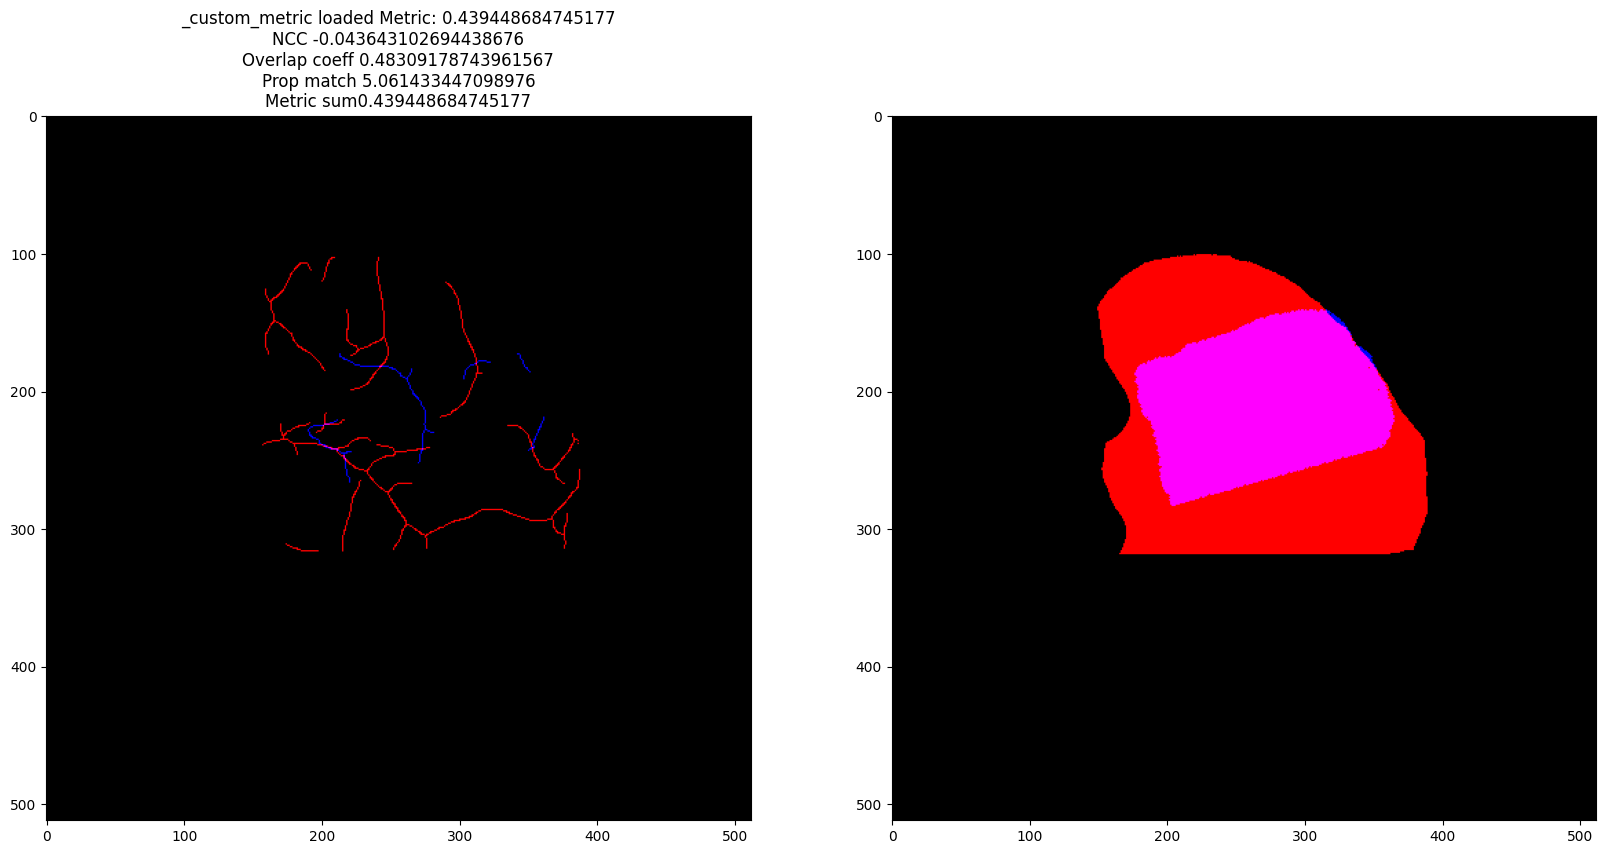

9
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/9/Reg_params_custom_metric.json


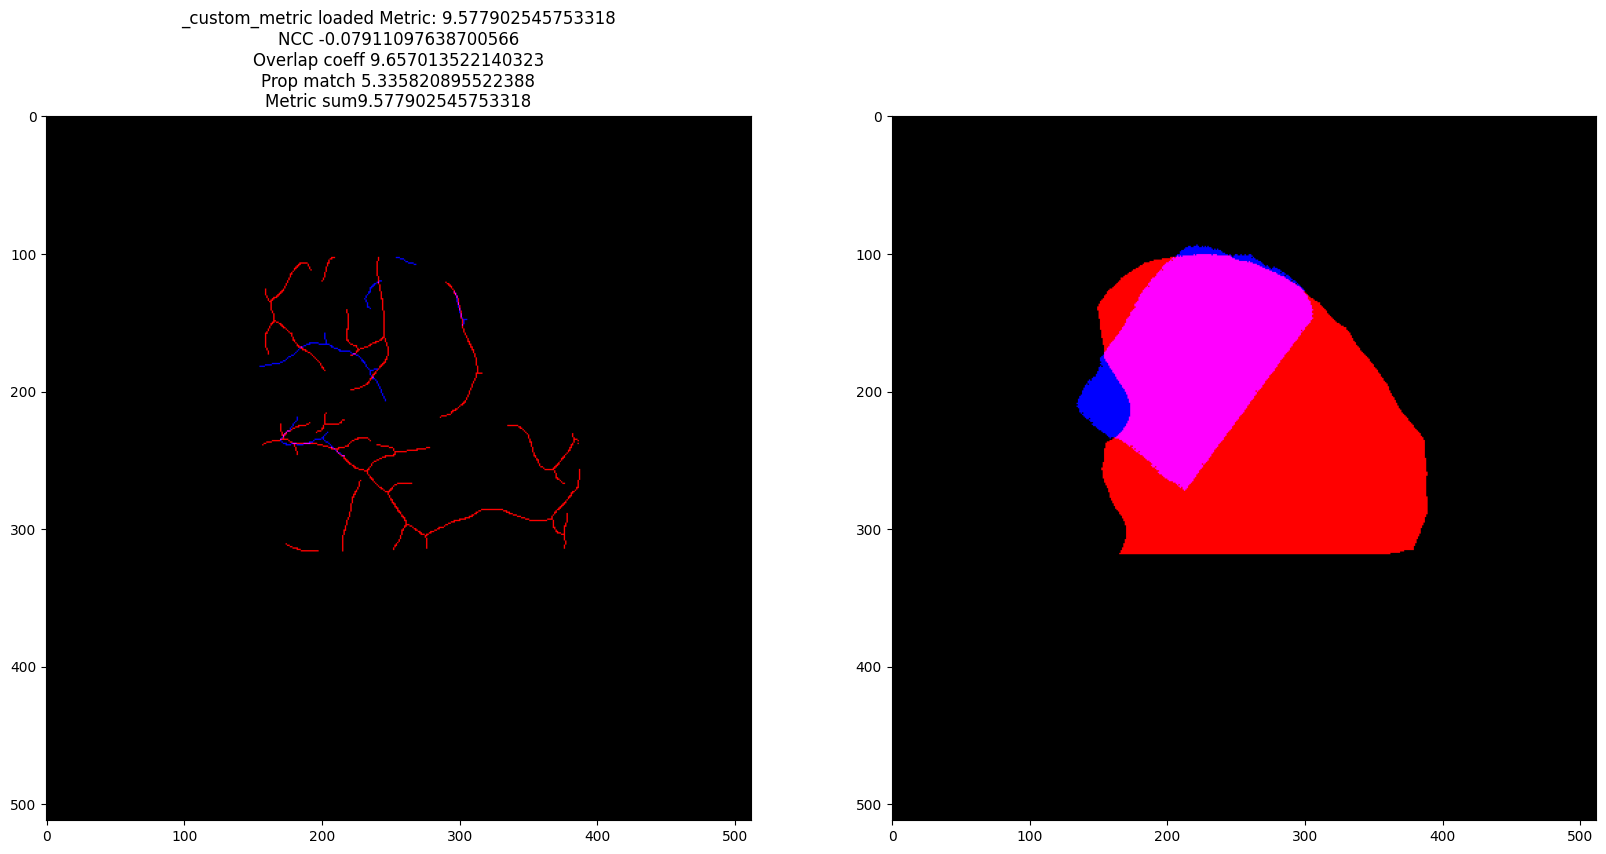

13
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/13/Reg_params_custom_metric.json


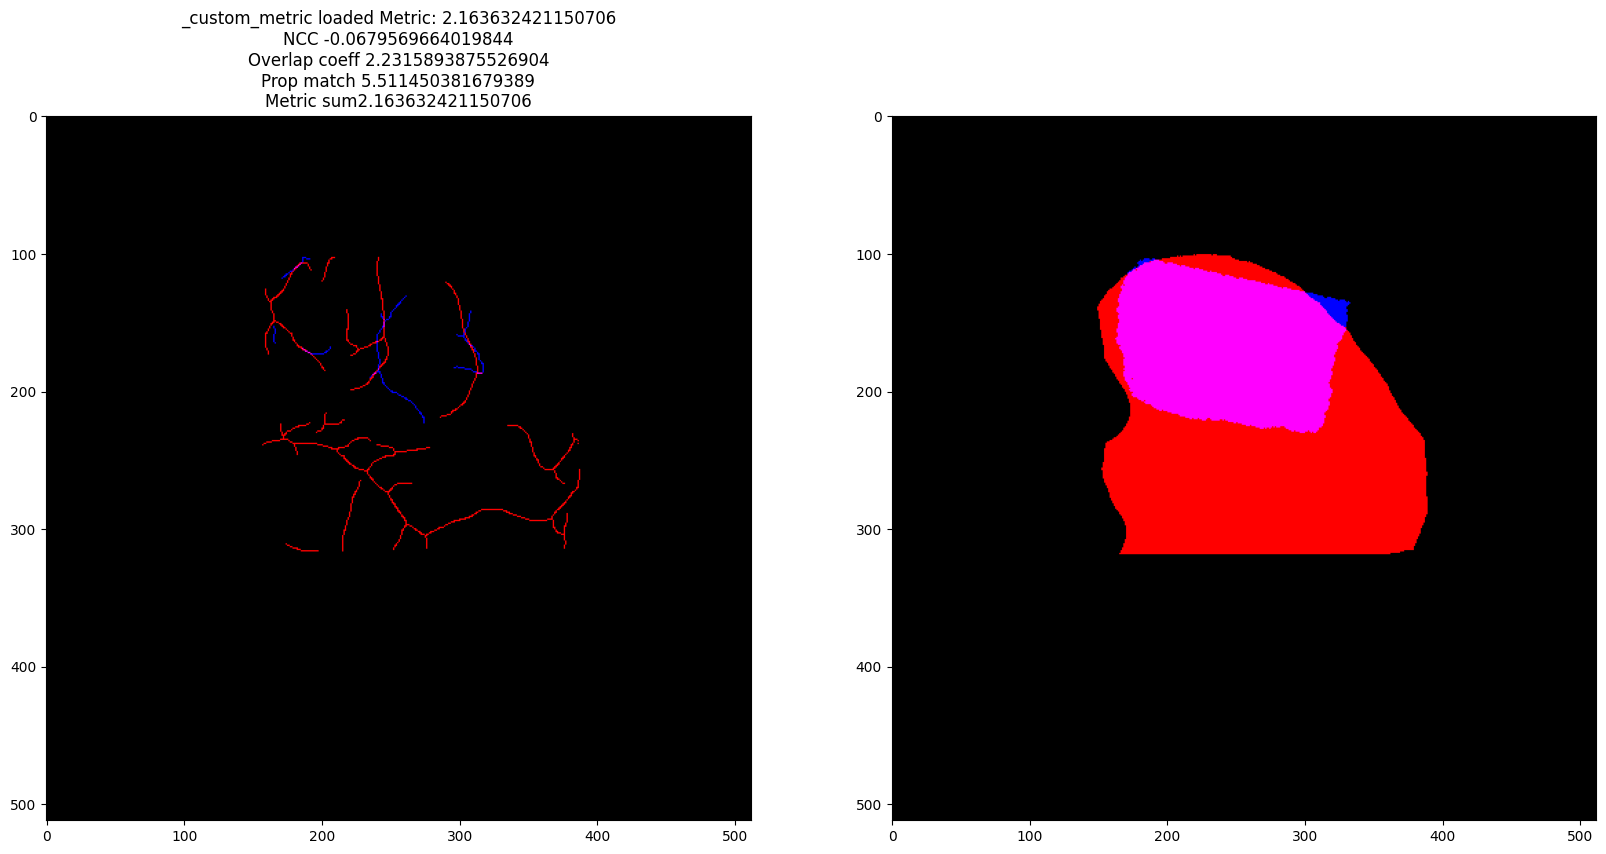

3
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/3/Reg_params_custom_metric.json


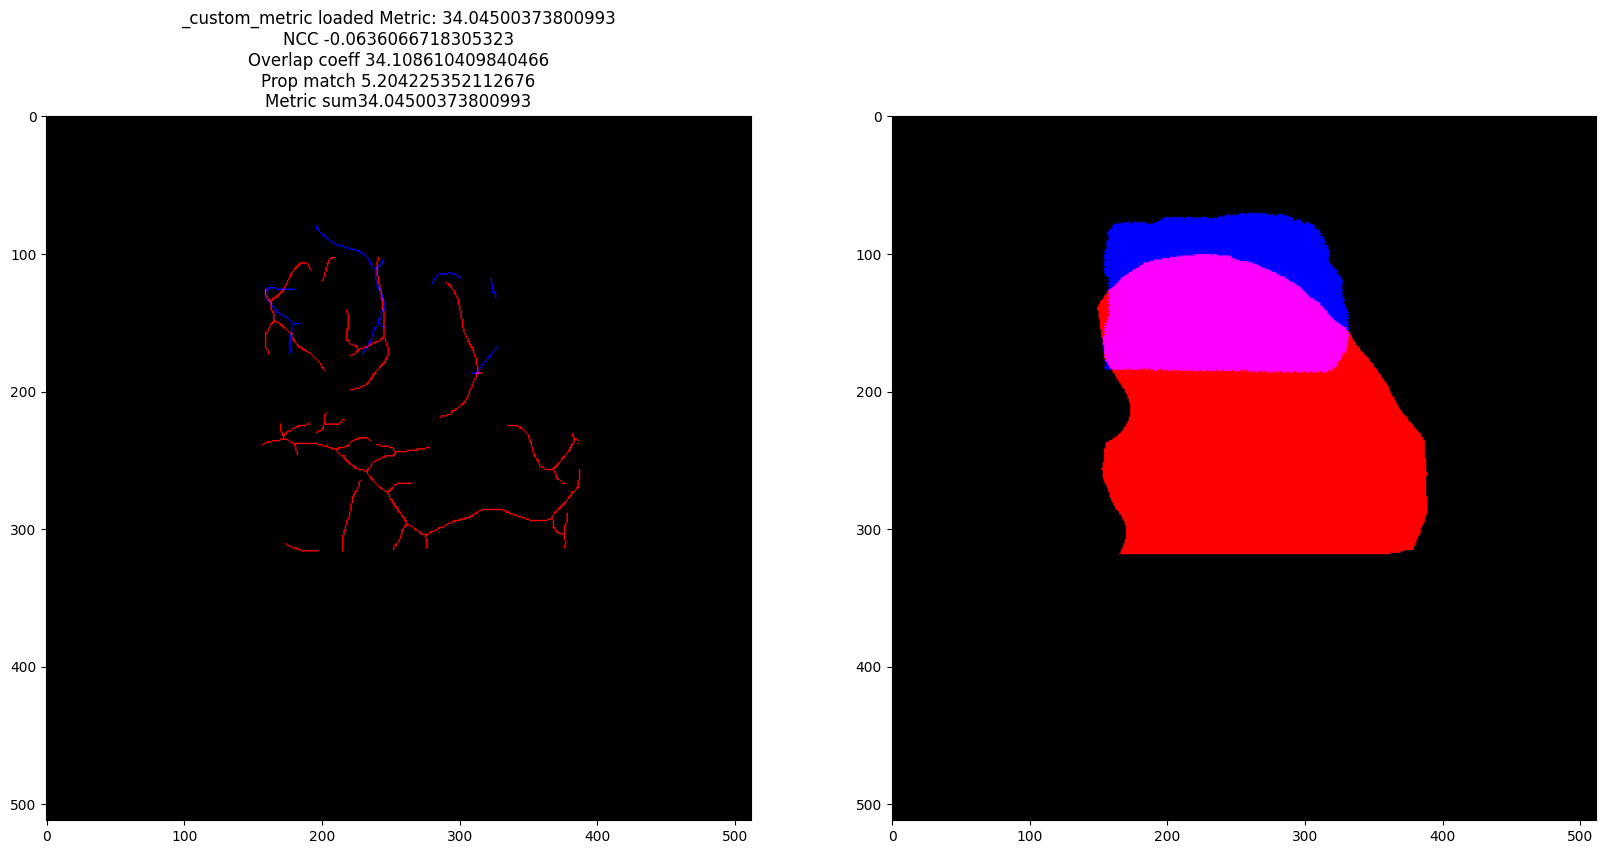

23
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/23/Reg_params_custom_metric.json


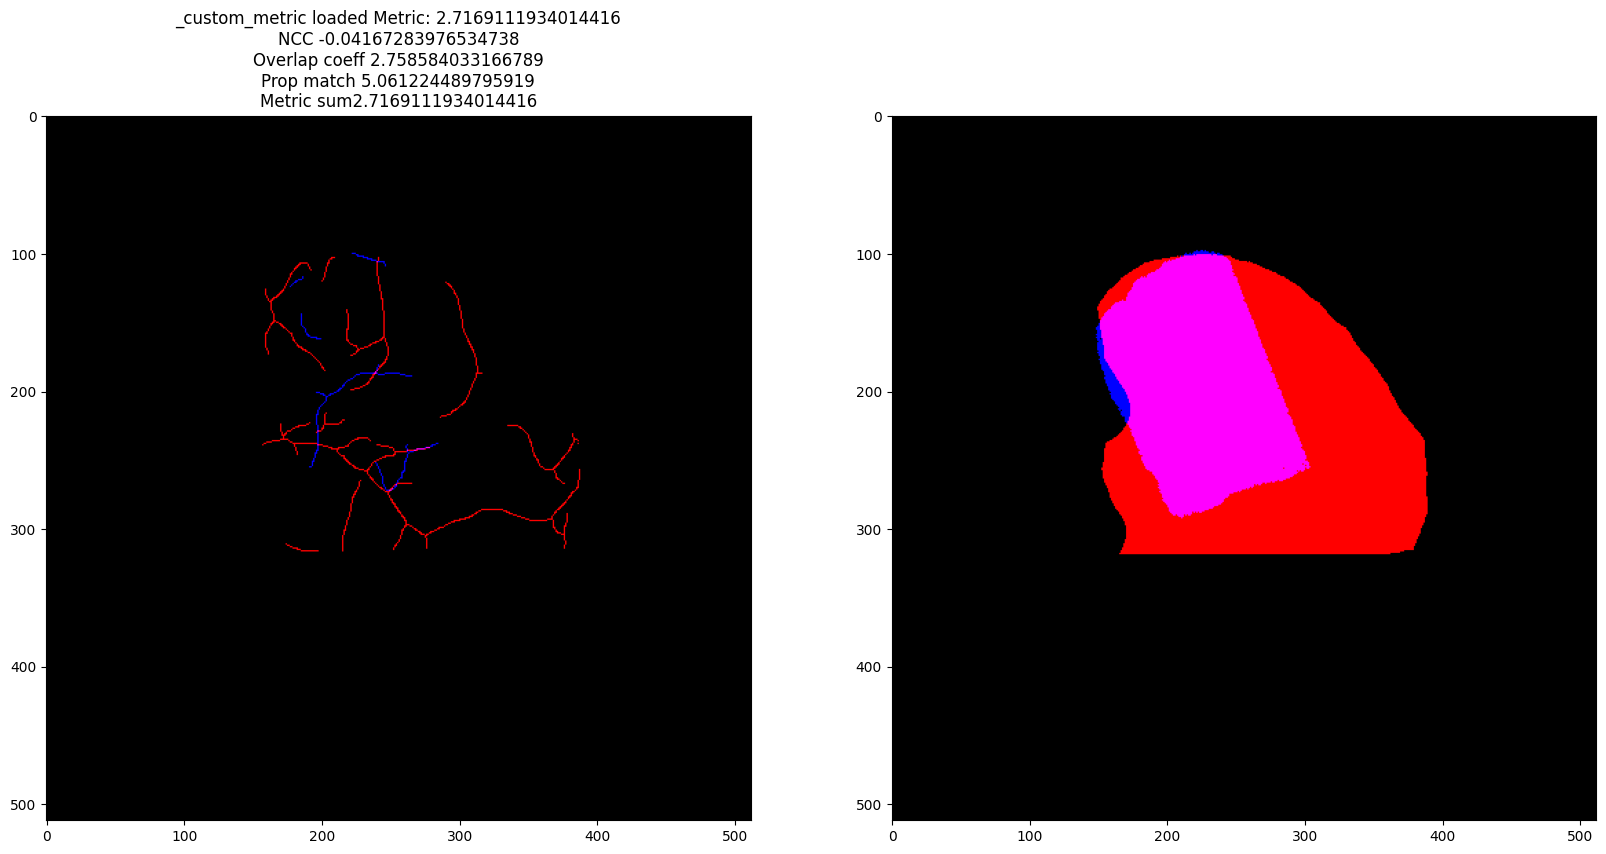

29
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/29/Reg_params_custom_metric.json


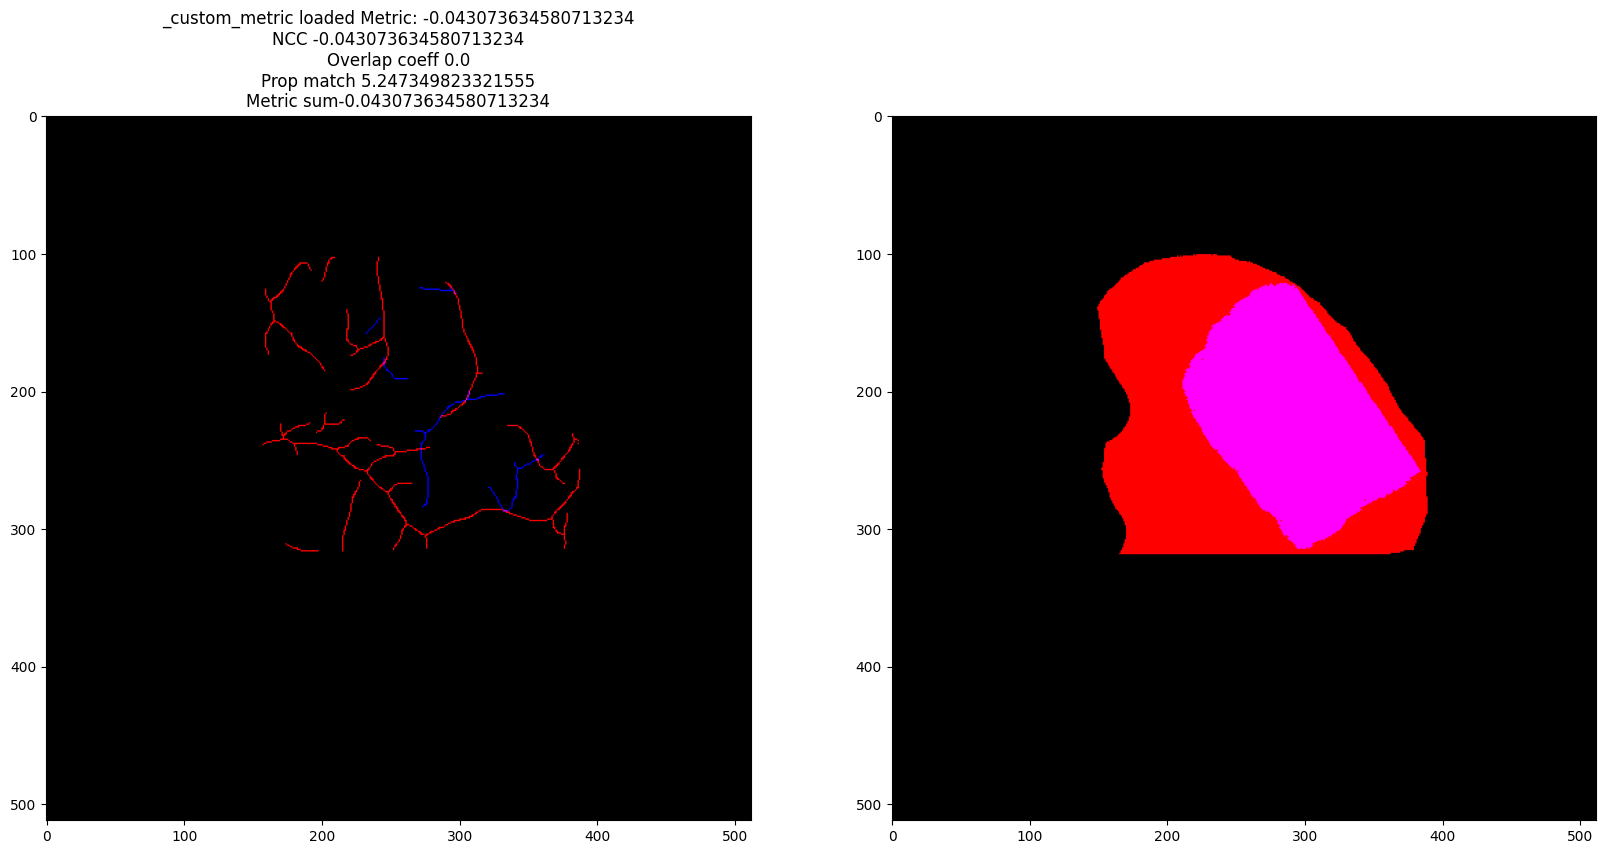

4
/home/caredda/Videos/Optical_MRI_data/P_059/results/Registration/Skeleton/Optics_thresh_80/4/Reg_params_custom_metric.json


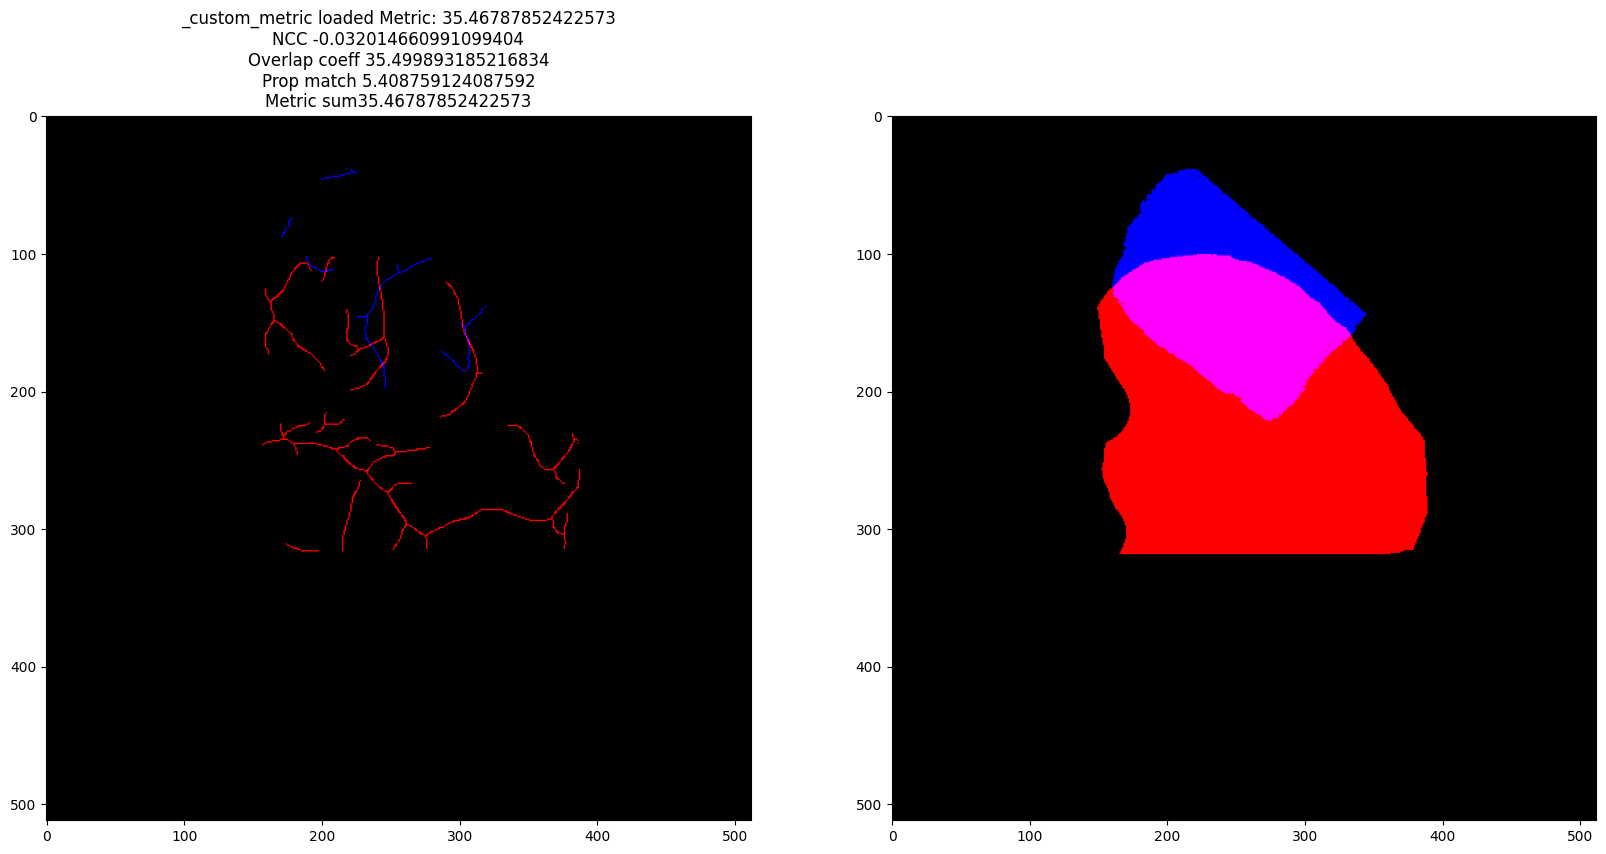

In [2]:
#Process registration
params.registration_type = "Skeleton"

#Load optical mask
filename_optics_mask = Mypath.main_path_optics+"mask.png"
mask = cv.imread(filename_optics_mask,cv.IMREAD_ANYCOLOR)/255

#Check if optical imaging is RGB or HSI
filename_initial_img_optics = Mypath.main_path_optics+"initial_img.png"
_,suffix_out_optics = is_RGB_optical_image(filename_initial_img_optics)


#Load MRI projection mask
filename_mask_MRI = Mypath.output_MRI_projection_dir+"Mask_Proj_MRI_around_tumor.nii.gz"
mask_MRI = itk.imread(filename_mask_MRI,itk.UC)
np_mask_MRI = itk.GetArrayFromImage(mask_MRI)
np_mask_MRI[np_mask_MRI>0] = 255
np_mask_MRI = np_mask_MRI.astype(np.uint8)

#Load skeleton MRI
filename_MRI_skeleton = Mypath.output_BV_segmentation_dir+"T1_proj_skeleton_origin_changed.nii.gz"
itk_MRI_skeleton = itk.imread(filename_MRI_skeleton)
np_MRI_skeleton = itk.GetArrayFromImage(itk_MRI_skeleton)*255
np_MRI_skeleton = np_MRI_skeleton.astype(np.uint8)



result_dir = get_registration_result_dir(Mypath, params)
result_dirs = glob.glob(result_dir+"*")


# itk.MeanSquaresImageToImageMetricv4
# itk.metrics.NormalizedCorrelationImageToImageMetricv4
# itk.MattesMutualInformationImageToImageMetricv4


suffix = ""
if params.use_custom_registration_metric:
    suffix = "_custom_metric"

for dir in result_dirs:
    print(os.path.basename(dir))
    reg_params = Registration_Params.load(dir+"/Reg_params"+suffix+".json")
    print(dir+"/Reg_params"+suffix+".json")
    title = suffix+" loaded Metric: "+str(reg_params.registration_metric)+"\n"
    
    
    #Load skeleton reg
    filename_reg = dir +"/registered_proj"+suffix+"_" + str(reg_params.angle) +suffix_out_optics+".nii.gz"
    itk_skeleton_reg = itk.imread(filename_reg)
    skeleton_reg = itk.GetArrayFromImage(itk_skeleton_reg)
    skeleton_reg[skeleton_reg>0.1] = 255
    skeleton_reg = skeleton_reg.astype(np.uint8)

    ksize=3
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE,(ksize,ksize))
    skeleton_reg = cv.morphologyEx(skeleton_reg, op=cv.MORPH_CLOSE, kernel=kernel)
    skeleton_reg = cv.ximgproc.thinning(skeleton_reg.astype(np.uint8))


    #Calculate NCC metric
    NCC_skeletons = itk_metric_value_fixed_space(itk.NormalizedCorrelationImageToImageMetric, itk_MRI_skeleton,  itk_skeleton_reg)


    # test
    test = (skeleton_reg - np_MRI_skeleton).astype(np.uint8)
    proportion_match =  np.count_nonzero(test)/np.count_nonzero(skeleton_reg)

    #Project optics mask on MRI
    error, mask_reg =  project_optical_image_on_MRI(Mypath, params, dir, mask)

    #Dilate masg reg
    mask_reg[mask_reg>0] =255
    mask_reg = mask_reg.astype(np.uint8)
    ksize=3
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE,(ksize,ksize))
    mask_reg = cv.morphologyEx(mask_reg, op=cv.MORPH_DILATE, kernel=kernel)

    out_skeleton = np.zeros((mask_reg.shape[0],mask_reg.shape[1],3),dtype=np.uint8)
    out_skeleton[:,:,0] = np_MRI_skeleton
    out_skeleton[:,:,2] = skeleton_reg


    out_mask = np.zeros((mask_reg.shape[0],mask_reg.shape[1],3),dtype=np.uint8)
    out_mask[:,:,0] = np_mask_MRI
    out_mask[:,:,2] = mask_reg


    #Calculate mask overlap
    overlap_mask_mri_optics_reg = overlap_coefficient(np_mask_MRI,mask_reg)
    

    title +="NCC "+str(NCC_skeletons)
    title +="\nOverlap coeff "+str(100*(1-overlap_mask_mri_optics_reg))
    title +="\nProp match "+str(proportion_match)
    title +="\nMetric sum"+str(NCC_skeletons + 100*(1-overlap_mask_mri_optics_reg))

    # print(error)
    # print(display_img.shape)


    plt.figure(figsize=(20,20))

    plt.subplot(121)
    plt.title(title)
    plt.imshow(out_skeleton)
    plt.subplot(122)
    plt.imshow(out_mask)
    plt.show()

# Plot registration metric

[get_best_MRI_keypoint] best MRI kpt is  9
92


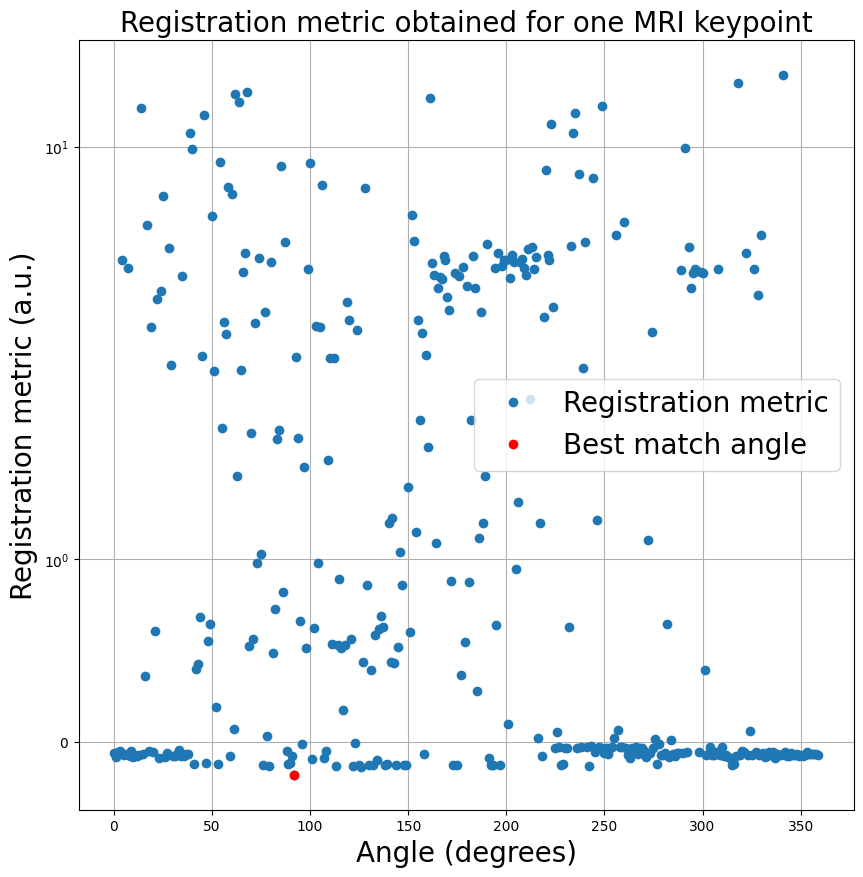

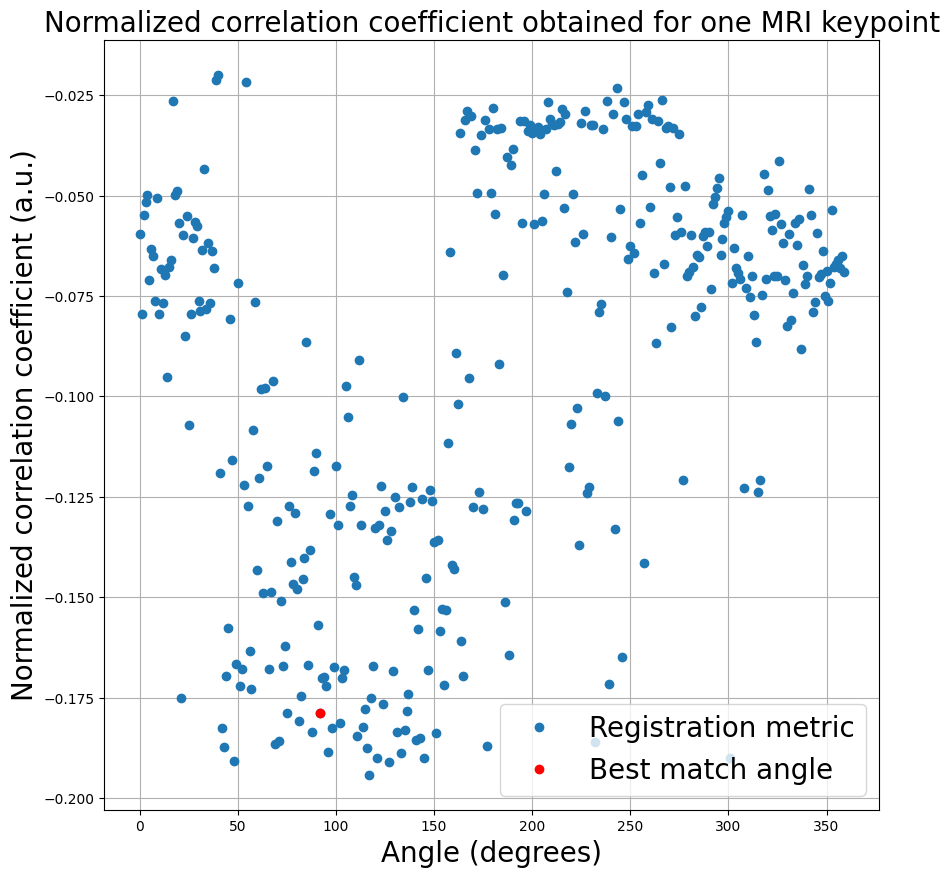

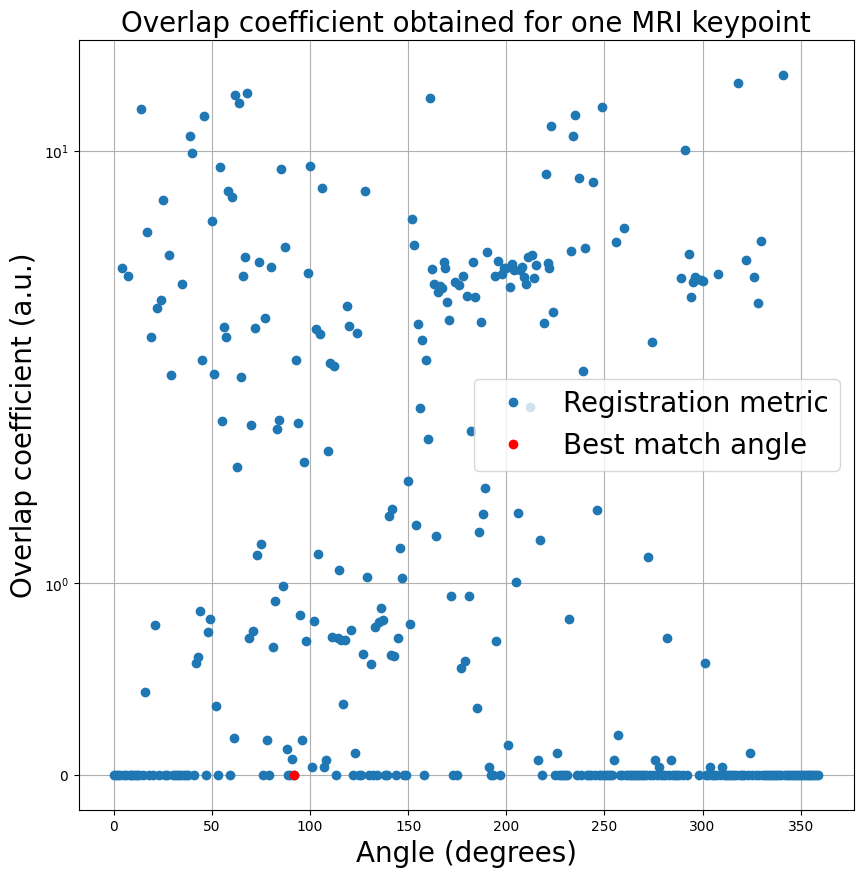

-0.17895919957804463
-0.17895919957804463
0.0


In [13]:
output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics

#Get best MRI keypoint



error,label_MRI_ktp = get_best_MRI_keypoint(Mypath, params)

#Get full directory
result_dir = get_registration_result_dir(Mypath, params)
result_dir += label_MRI_ktp

#Load initial optical image
filename_initial_img_optics = main_path_optics+"initial_img.png"

ft = 20

if os.path.exists(filename_initial_img_optics):
    #Check if optical imaging is RGB or HSI
    _,suffix_out_optics = is_RGB_optical_image(filename_initial_img_optics)

    #Load metric
    
    NCC_val = np.loadtxt(result_dir +"/NCC"+suffix_out_optics+".txt")
    overlap = np.loadtxt(result_dir +"/overlap"+suffix_out_optics+".txt")
    custom_metric = NCC_val + overlap
    
    

    #Get best match
    angle = np.nanargmin(custom_metric)
    print(angle)

    plt.figure(figsize=(10,10))
    plt.plot(np.arange(0,360),custom_metric, 'o', label='Registration metric')
    plt.plot(angle,custom_metric[angle], 'ro', label='Best match angle')
    plt.xlabel("Angle (degrees)",fontsize=ft)
    plt.ylabel("Registration metric (a.u.)",fontsize=ft)
    plt.title("Registration metric obtained for one MRI keypoint",fontsize=ft)
    plt.legend(loc="best",fontsize=ft)
    plt.grid()
    plt.yscale("symlog")
    plt.show()


    plt.figure(figsize=(10,10))
    plt.plot(np.arange(0,360),NCC_val, 'o', label='Registration metric')
    plt.plot(angle,NCC_val[angle], 'ro', label='Best match angle')
    plt.xlabel("Angle (degrees)",fontsize=ft)
    plt.ylabel("Normalized correlation coefficient (a.u.)",fontsize=ft)
    plt.title("Normalized correlation coefficient obtained for one MRI keypoint",fontsize=ft)
    plt.legend(loc="best",fontsize=ft)
    plt.grid()
    plt.show()

    plt.figure(figsize=(10,10))
    plt.plot(np.arange(0,360),overlap, 'o', label='Registration metric')
    plt.plot(angle,overlap[angle], 'ro', label='Best match angle')
    plt.xlabel("Angle (degrees)",fontsize=ft)
    plt.ylabel("Overlap coefficient (a.u.)",fontsize=ft)
    plt.title("Overlap coefficient obtained for one MRI keypoint",fontsize=ft)
    plt.legend(loc="best",fontsize=ft)
    plt.grid()
    plt.yscale("symlog")

    plt.show()
    
    print(custom_metric[angle])
    print(NCC_val[angle])
    print(overlap[angle])



# Project Optics image/stats on T1 [Create projection]
Problem: décallage en rotation quand use_upscaled_images = False 

Success
Success


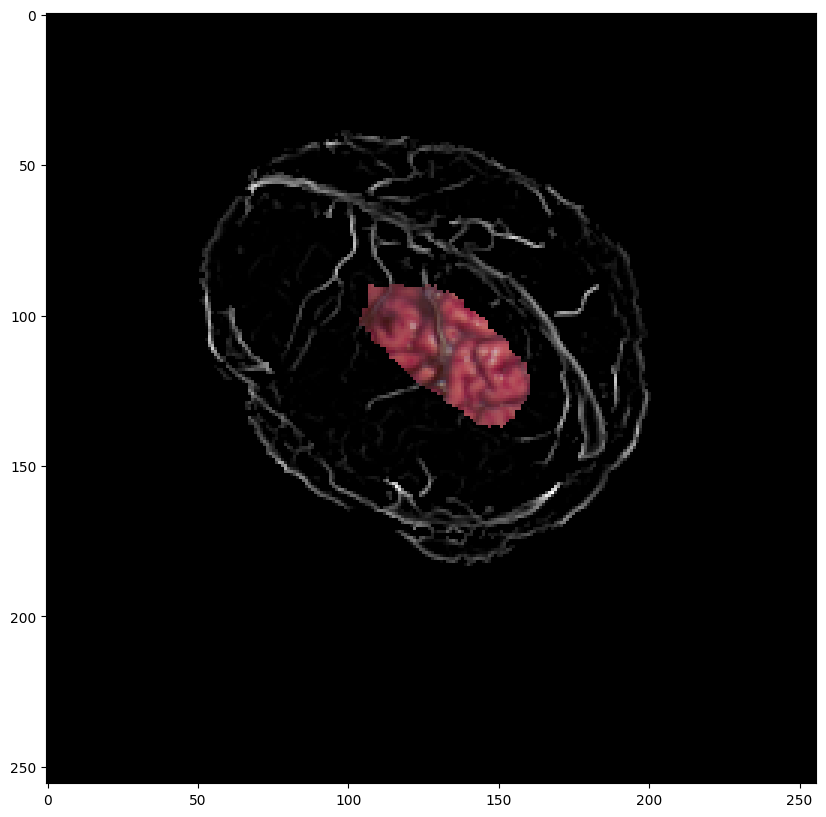

In [2]:
#Project optical image/stats on MRI projection
error = main_project_optical_image_on_MRI(Mypath, params)
print(error)

#plot results
error,display2 = main_plot_Optical_image_projected_on_MRI(Mypath)
print(error)


plt.figure(figsize=(10,10))
plt.imshow(display2)
plt.show()



#Project optical image/stats on MRI projection
#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")


# # fMRI_filenames=[dir_fMRI+"r_RS_SCA_inferenceL_motor_rotated_Mask_proj.png",
# #                 dir_fMRI+"r_RS_SCA_inferenceR_motor_rotated_Mask_proj.png"]
# # fOptics_filenames = [dir_foptics+"RGB_inferenceL_reg_motor_mask.png",
# #                      dir_foptics+"RGB_inferenceR_reg_motor_mask.png"]

# # fMRI_filenames=[dir_fMRI+"r_RS_SCA_inferenceL_sensory_rotated_Mask_proj.png",
# #                 dir_fMRI+"r_RS_SCA_inferenceR_sensory_rotated_Mask_proj.png"]
# # fOptics_filenames = [dir_foptics+"RGB_inferenceL_reg_sensory_mask.png",
# #                      dir_foptics+"RGB_inferenceR_reg_sensory_mask.png"]


_fMRI_filenames = [Mypath.main_path+"/MRI/fMRI/inferences/"+"zone_MGfwe.nii"]        #r_zone_MGfwe_Mask_proj.png
_fOptics_filenames = [Mypath.main_path+"/optics/foptics_"+suffix_out_optics+"/"+"Z_stats_Hb.txt"]  #dir_foptics+"Z_stats_Hb_mask.png"
 




colors_fOptics = [(255,0,0),(0,0,255)]
colors_fMRI = [(255,255,0),(0,215,255)]

error, display = main_plot_fOptics_fMRI_stats_projected_on_MRI(Mypath,
                                                 _fMRI_filenames=_fMRI_filenames,
                                                 _fOptics_filenames=_fOptics_filenames,
                                                 colors_fMRI=colors_fMRI,
                                                 colors_fOptics=colors_fOptics)

if error == "Sucess":
    plt.figure(figsize=(20,20))
    plt.imshow(cv.cvtColor(display,cv.COLOR_BGR2RGB))
    plt.show()



# Create Optics volume registered in T1 space

In [3]:
#Create optical volume in T1 space
error = main_reconstruct_Optics_volume(Mypath)
print(error)

#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")
open_MRIcroGL_with_overlay(Mypath.output_dir+"r_T1_bet.nii.gz", Mypath.output_dir + "Projection/Rec_Optical_T1"+suffix_out_optics+".nii.gz")


Success


Gtk-Message: 16:45:52.291: Failed to load module "pk-gtk-module"

(MRIcroGL:529845): Gtk-WARNING **: 16:45:52.370: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:529845): Gtk-WARNING **: 16:45:52.370: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:529845): Gtk-WARNING **: 16:45:52.371: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:529845): Gtk-WARNING **: 16:45:52.371: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:529845): Gtk-WARNING **: 16:45:52.371: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work 

If there is a long delay at launch, ensure full GTK2 install: "sudo apt-get install appmenu-gtk2-module"
Unable to find AFNI_ATLAS_PATH 
Loading preferences /home/caredda/.MRIcroGL12.ini
uint8 range 0...255
uint8 window 0...250
Init time 0
Set Min/Max Window 0..250 time 0
Update RGBA time 0
Reading script /home/caredda/DVP/CREATIS_Optics_MRI_registration/Registration/module/display_MRIcroGL.py
ResourceDir: /home/caredda/Soft/MRIcroGL_linux1804/MRIcroGL/Resources PyLib: /home/caredda/Soft/MRIcroGL_linux1804/MRIcroGL/Resources
Loading modules....
Done Loading modules....
Load time 36
float range 0..518796.3125
float window 0...0
Init time 29
Set Min/Max Window 0..518796.3125 time 5
Update RGBA time 10
Load time 25
float range 0..212.78567504882813
float window 0...0
Init time 29
gradientTexture3D proxy test 256x256x130
blur proxy test 256x256x130
GPU Gradient time 31
blur proxy test 256x256x130
GPU Gradient time 16
blur proxy test 256x256x130
GPU Gradient time 15


# [Debug] Test refine projection (by taking into account the brain curvature)

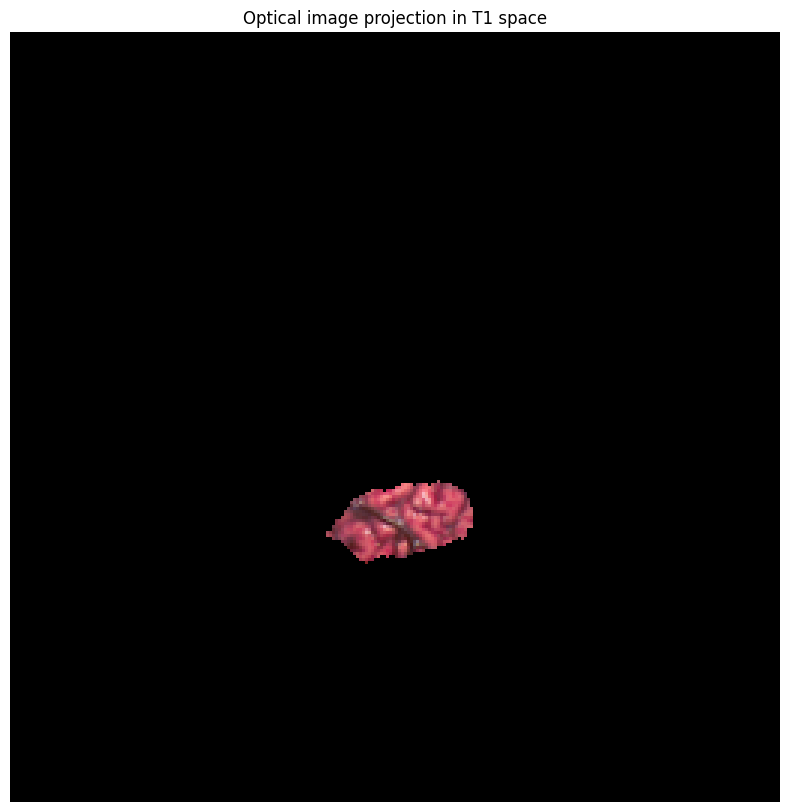

In [4]:
main_path_optics = Mypath.main_path_optics
output_dir = Mypath.output_dir
output_MRI_projection_dir = Mypath.output_MRI_projection_dir


#Check if optical imaging is RGB or HSI
filename_optics = main_path_optics+"initial_img.png"
if not os.path.exists(filename_optics):
    print("Optical image not found at")

_,suffix_out_optics = is_RGB_optical_image(filename_optics)

#Load optical volumes
B_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_B"+suffix_out_optics+".nii.gz", itk.F)
G_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_G"+suffix_out_optics+".nii.gz", itk.F)
R_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_R"+suffix_out_optics+".nii.gz", itk.F)


filename_MRI_surface = output_MRI_projection_dir+'surface_mask_rotated.nii.gz'
filename_tumor = output_MRI_projection_dir+'Tumor_rotated.nii.gz'

surface = itk.imread(filename_MRI_surface, itk.F)
tumor = itk.imread(filename_tumor, itk.F)

# Get numpy arrays
np_B_vol = itk.GetArrayFromImage(B_vol)
np_G_vol = itk.GetArrayFromImage(G_vol)
np_R_vol = itk.GetArrayFromImage(R_vol)

np_surface = itk.GetArrayFromImage(surface)
np_tumor = itk.GetArrayFromImage(tumor)


# Calculate projection
np_B_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_B_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)

np_G_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_G_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)

np_R_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_R_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)


BGR_proj = np.zeros((np_B_vol_projection.shape[0], np_B_vol_projection.shape[1], 3), dtype=np.uint8)
BGR_proj[:, :, 0] = np_B_vol_projection.astype(np.uint8)
BGR_proj[:, :, 1] = np_G_vol_projection.astype(np.uint8)
BGR_proj[:, :, 2] = np_R_vol_projection.astype(np.uint8)

plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(BGR_proj,cv.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Optical image projection in T1 space")
plt.show()









# [TEMP FOR ADITHEP] Create MRI seed image
1) Create mask
2) Run project optics image/stats on T1
3) Run Create Optics volume

In [ ]:

#seed image
filename_optics = Mypath.main_path_optics+"initial_img.png"
in_img = cv.imread(filename_optics)

#Seed image
pos = (200,379)
seed = np.zeros((in_img.shape[0],in_img.shape[1]),dtype=np.uint8)
seed[pos[0]-10:10+pos[0],pos[1]-10:10+pos[1]] = 255

np.savetxt(Mypath.main_path_optics+"foptics/RGB_seed_sensory.txt",seed)


# Project MRI on optical image

-134 -127
-134 -127
Success
Success


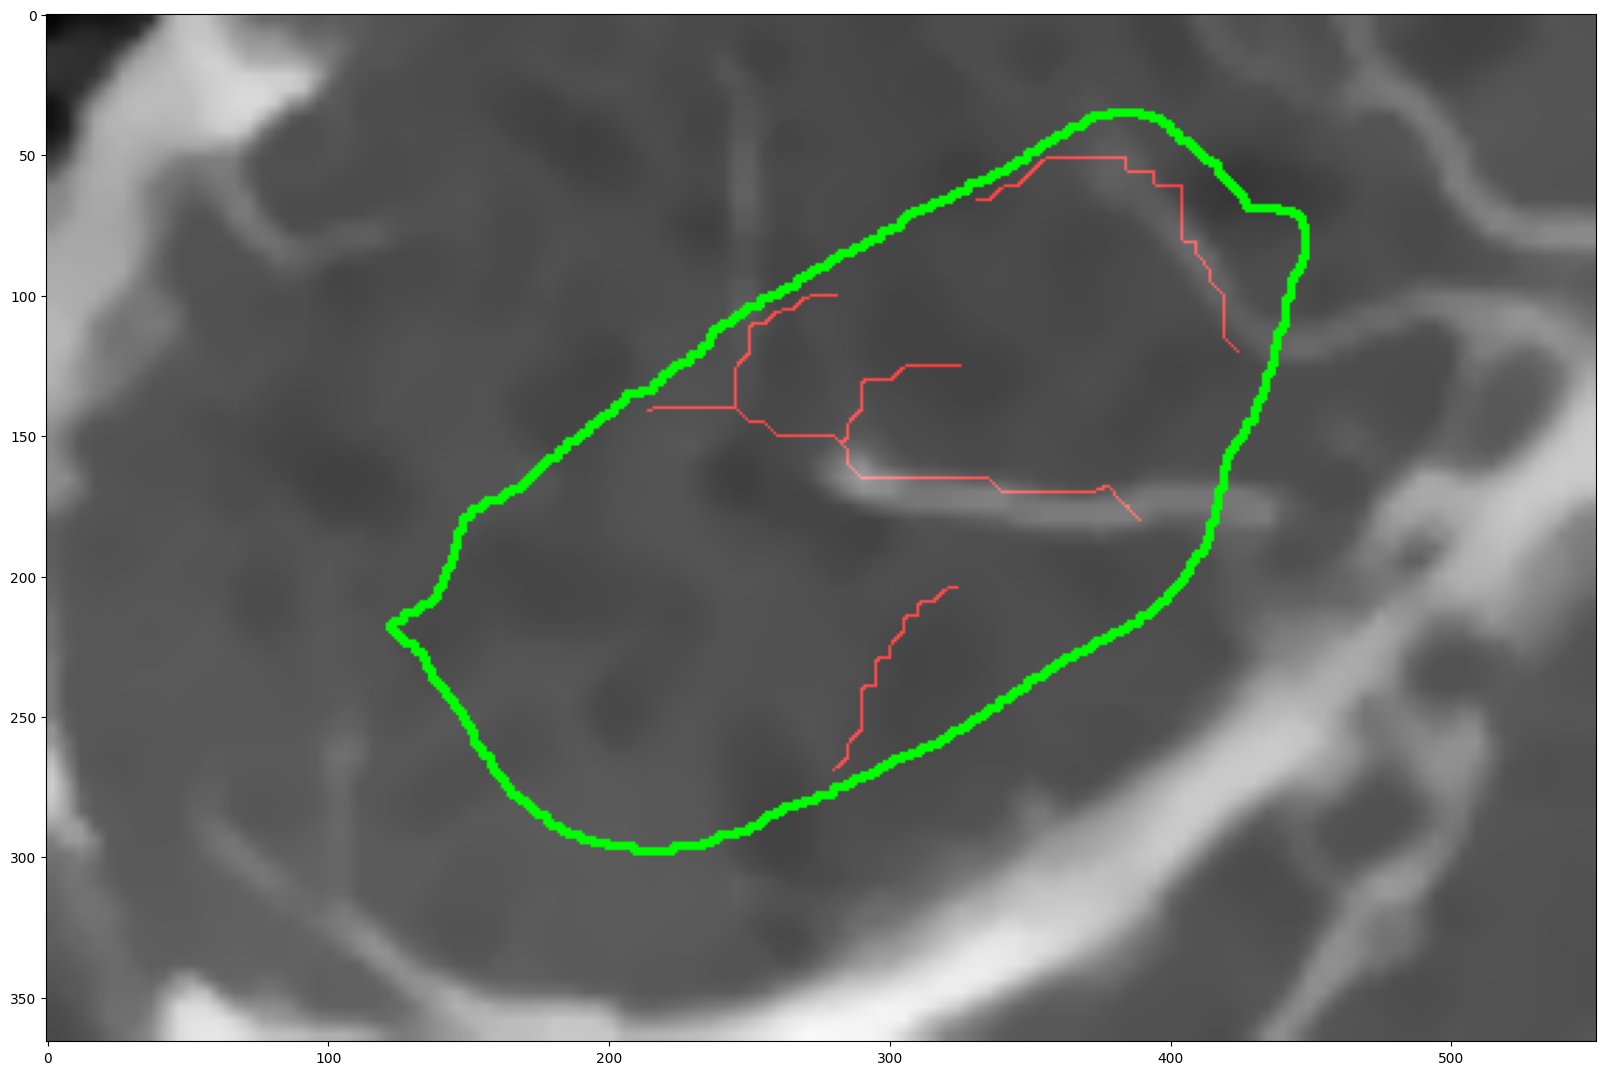

['/home/caredda/Videos/Optical_MRI_data/P_023/optics/foptics/Z_stats_Hb.txt']


In [2]:
#Project MRI on optics space
error = main_project_MRI_in_optics_space(Mypath, params)
print(error)

#Plot results
error,display = main_plot_MRI_projected_on_Optics_space(Mypath)
print(error)

plt.figure(figsize=(20,20))
plt.imshow(display)
plt.show()




#Project optical image/stats on MRI projection
#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")
dir_fMRI = Mypath.output_dir + "Projection/fMRI/"
dir_foptics = Mypath.output_dir + "Projection/foptics_"+suffix_out_optics+"/"


fMRI_filenames = [Mypath.main_path+"/MRI/fMRI/inferences/"+"zone_MGfwe.nii"]        #r_zone_MGfwe_Mask_proj.png
fOptics_filenames = [Mypath.main_path_optics+"foptics/"+"Z_stats_Hb.txt"]  #dir_foptics+"Z_stats_Hb_mask.png"
print(fOptics_filenames)

colors_fOptics = [(255,0,0),(0,0,255)]
colors_fMRI = [(255,255,0),(0,215,255)]

error, display = main_plot_fOptics_fMRI_stats_projected_on_optics(Mypath,
                                                 _fMRI_filenames=fMRI_filenames,
                                                 _fOptics_filenames=fOptics_filenames,
                                                 colors_fMRI=colors_fMRI,
                                                 colors_fOptics=colors_fOptics)

if error == "Success":
    plt.figure(figsize=(20,20))
    plt.imshow(cv.cvtColor(display,cv.COLOR_BGR2RGB))
    plt.show()

# Registration validation

Patient ID P_025


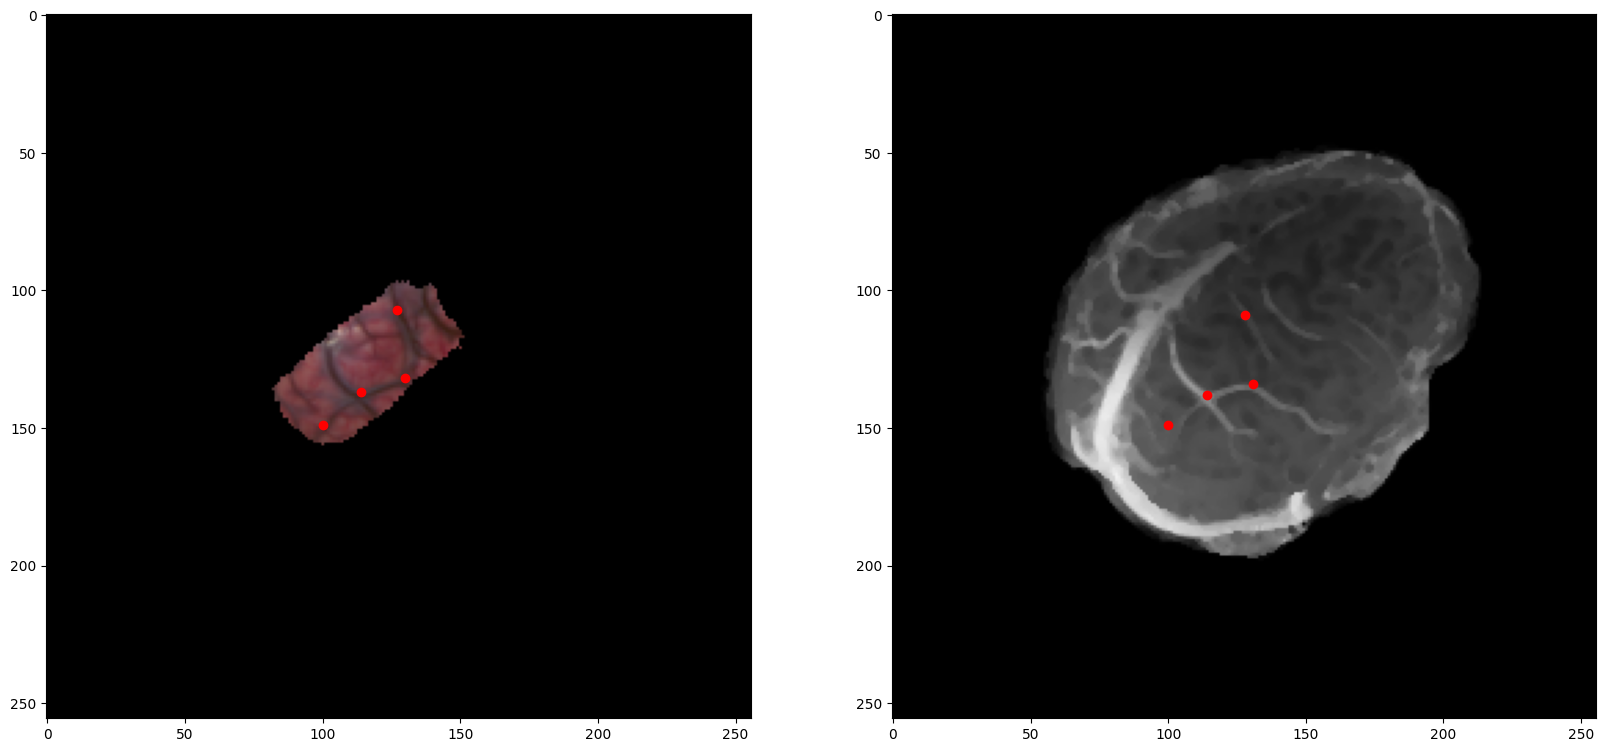

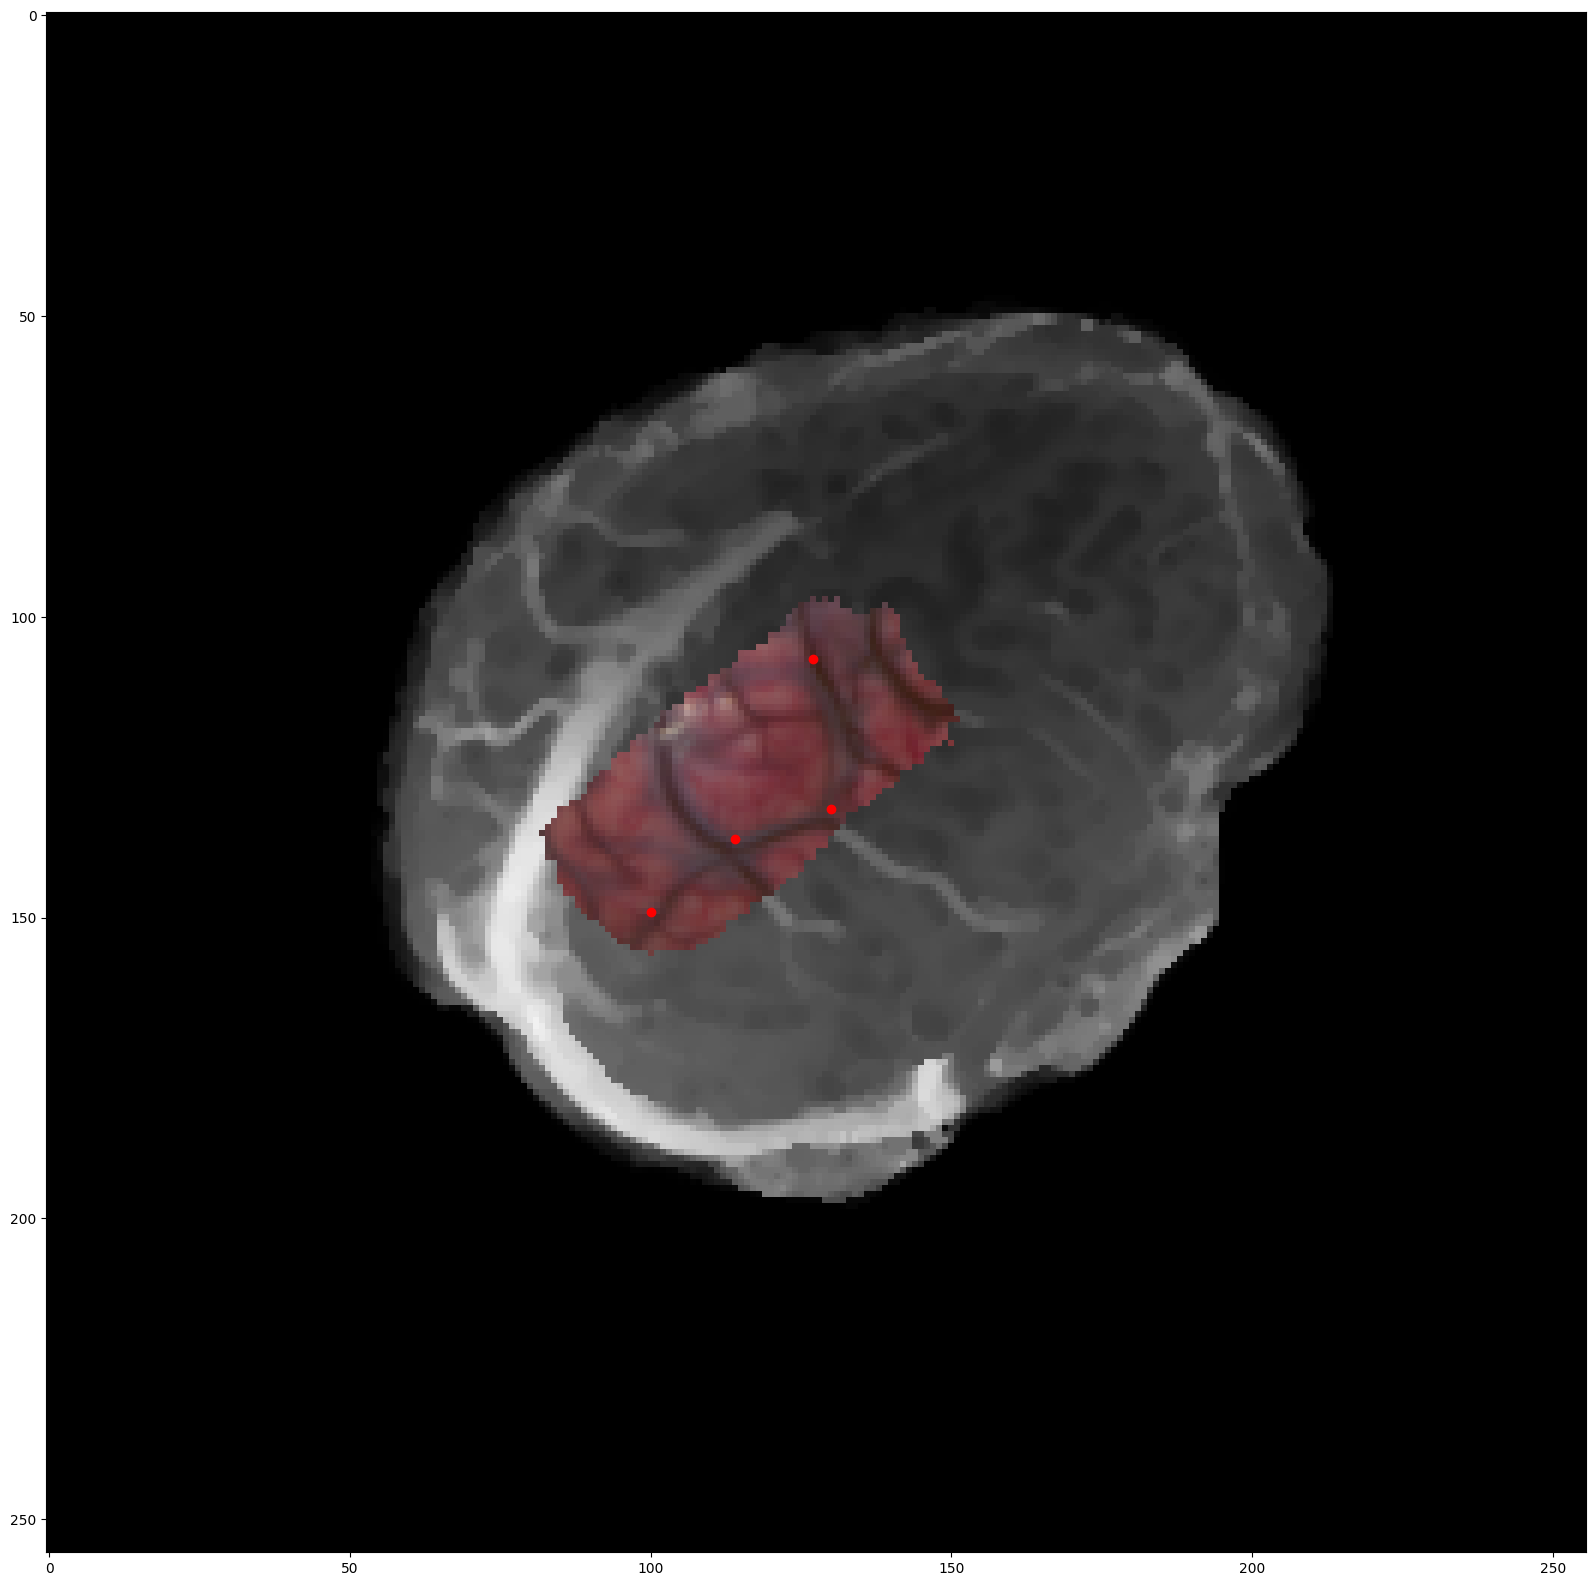

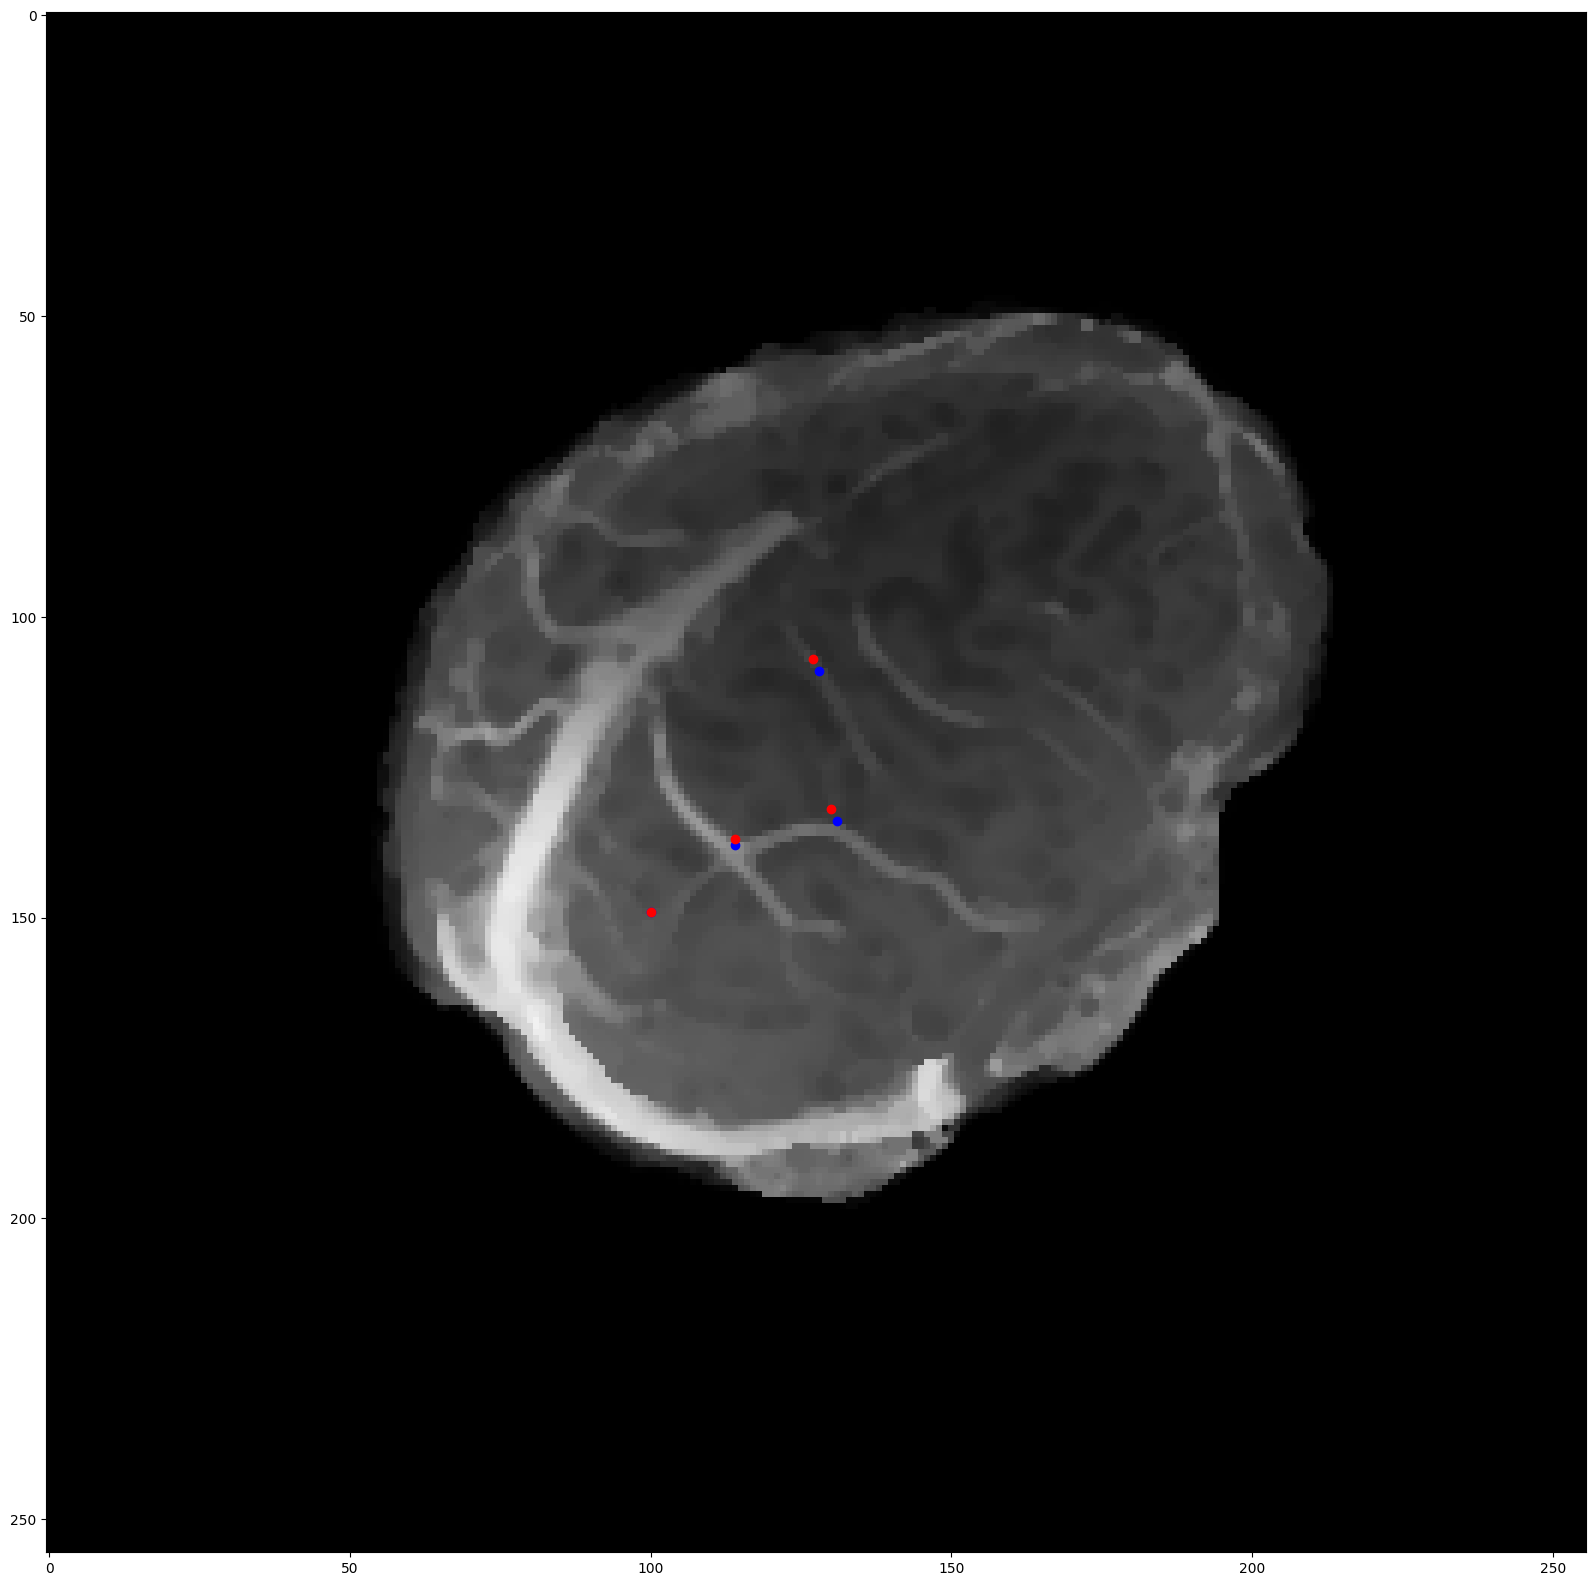

In [7]:
output_dir = Mypath.output_dir

print("Patient ID",Patient_ID_array[id_patient])

#Load images
mri = cv.imread(output_dir+"Projection/MRI_proj.png",cv.IMREAD_ANYCOLOR)
optics = cv.imread(output_dir+"Projection/RGB_registered_on_MRI.png")
mri_optics = cv.imread(output_dir+"Projection/Optical_img_projected_on_MRI.png")


#Load landmarks
points_optics = np.loadtxt(output_dir+"verification_landmarks/optics.txt")#.astype(int)
points_mri = np.loadtxt(output_dir+"verification_landmarks/mri.txt")#.astype(int)



plt.figure(figsize=(20,20))
plt.subplot(121)
plt.imshow(cv.cvtColor(optics, cv.COLOR_BGR2RGB))
for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.subplot(122)
plt.imshow(mri)
for i in range(points_mri.shape[0]):
    plt.plot(points_mri[i,0],points_mri[i,1],'ro')
plt.show()


plt.figure(figsize=(20,20))
plt.imshow(cv.cvtColor(mri_optics, cv.COLOR_BGR2RGB))
for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.show()


plt.figure(figsize=(20,20))
plt.imshow(mri)
for i in range(points_mri.shape[0]):
    plt.plot(points_mri[i,0],points_mri[i,1],'bo')

for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.show()

# Create mesh of T1 and registered optical file

In [ ]:

output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics


# Load the MRI data
nsub = 3
mesh_mri = process_mesh(output_dir+'r_T1_bet.nii.gz',nsub)
mesh_optical = process_mesh(output_dir +"Rec_Optical_T1.nii.gz",nsub)

save_path = "/home/caredda/temp/"

# Save the mesh to an STL file
mesh_mri.save(save_path+"MRI_mesh.stl")
mesh_optical.save(save_path+"Optics_mesh.stl")

#save texture for optics
input_img = cv.imread(main_path_optics+"initial_img.png")
mask = (cv.imread(main_path_optics+"mask.png",cv.IMREAD_GRAYSCALE)/255).astype(np.uint8)
for i in range(input_img.shape[2]):
    input_img[:,:,i] *= mask
cv.imwrite(save_path+"texture_optics.png",input_img)




# Mean ans std for validation landmarks

In [ ]:
metric_m = np.array([1.75, 1.32, 1.22, 1.30, 2.25, 1.77, 0.85, 1.09, 2.69, 1.89, 1.68, 2.21, 1.65, 1.22, 1.08, 1.06, 1.56, 1.7, 2.13, 2.38, 1.62, 1.48, 2, 0.98,1.72])
metric_s = np.array([0.58, 1.27, 0.33, 0.22, 0.95, 0.48, 0.67, 0.99, 0.77, 1.08, 0.56, 1, 0.15, 0.46, 0.96, 0.22, 0.48, 1.72, 0.23, 0.49, 0.49, 0.63, 0.8])

reso = np.array([1.17, 1.27, 0.46, 0.46, 0.47, 0.46, 0.46, 0.5, 1, 0.46, 0.46, 0.46, 0.56, 0.9, 0.46, 0.46, 0.46, 0.46, 1.17, 0.46, 0.34, 0.44, 0.24, 0.44, 0.49])

print("MRI resolution", reso.mean(), reso.std())
print("Mean metric", metric_m.mean(),metric_m.std())
print("Std metric", metric_s.mean(), metric_s.std())

# Plot all results in one big image

In [22]:
from module.utils import *


path = "/home/caredda/Videos/Optical_MRI_data/"

Patient_ID_array = np.array(["P_023", "P_025","P_028","P_031","P_032", "P_033", "P_035", "P_040","P_045","P_048","P_051","P_054","P_055","P_058","P_059","P_060","P_061","P_064","P_066","P_068","P_075","P_077","P_078","P_081","P_083"])  

print(Patient_ID_array.shape)

#Load first images
optics = cv.imread(path + Patient_ID_array[0] + "/results/Projection/Optical_img_projected_on_MRI2.png")

#resize
f = 10
new_shape = (int(f*optics.shape[1]),int(f*optics.shape[0]))
optics = cv.resize(optics, (int(f*optics.shape[1]),int(f*optics.shape[0])), interpolation= cv.INTER_LINEAR)

nb_row = 9
nb_col = 3
space = f*30
out = np.zeros(((new_shape[1]+space)*nb_row, (new_shape[0]+space)*nb_col + space*(nb_col-1),3),dtype = optics.dtype)

id = 0

for r in range(nb_row):
    for c in range(nb_col):
        if id>=25:
            break
        p = Patient_ID_array[id]
        id +=1

        #Load images
        optics = cv.imread(path + p + "/results/Projection/Optical_img_projected_on_MRI2.png")



        #resize image
        optics = cv.resize(optics, (new_shape[0],new_shape[1]), interpolation= cv.INTER_LINEAR)

        #Copy to output
        r_start = r*(new_shape[1]+space)+space
        r_stop = r_start+new_shape[1]
        c_start = c*(new_shape[0]+space)
        c_stop = c_start + new_shape[0]
        out[r_start:r_stop,c_start:c_stop,:] = optics

cv.imwrite(path+"results.png",out)




(25,)


True

# Display parameters

In [ ]:
Patient_ID_array = np.array(["P_023", "P_025","P_028","P_031","P_032", "P_033", "P_035", "P_040","P_045","P_048","P_051","P_054","P_055","P_058","P_059","P_060","P_061","P_064","P_066","P_068","P_075","P_077","P_078","P_081","P_083"])  


thresh_optics = []
thresh_MRI = []
tumor_ROI_enlarge_factor = []
space_between_kpt_mm = []

# min_vessel_size_optics = []
# max_vessel_size_optics = []
# min_vessel_size_MRI = []
# max_vessel_size_MRI = []
# ksize_mm_kernal_specular_reflection_optics = []


for p in Patient_ID_array:
    Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + p, RGB_optics=True)

    # Load parameters
    params_file = Mypath.main_path+"/Params.json"
    params = Params.load(params_file)


    thresh_optics.append(params.thresh_optics)
    thresh_MRI.append(params.thresh_MRI)
    space_between_kpt_mm.append(params.space_between_kpt_mm)
    # min_vessel_size_optics.append(params.sigma_minimum_mm_optics)
    # max_vessel_size_optics.append(params.sigma_maximum_mm_optics)
    # min_vessel_size_MRI.append(params.sigma_minimum_mm_MRI)
    # max_vessel_size_MRI.append(params.sigma_maximum_mm_MRI)
    # ksize_mm_kernal_specular_reflection_optics.append(params.ksize_mm_kernal_specular_reflection_optics)

    # print("$"+str(params.thresh_optics)+" / "+str(params.thresh_MRI)+"$")
    p = params.tumor_ROI_enlarge_factor
    if p<1:
        p=1
    tumor_ROI_enlarge_factor.append(p)

tumor_ROI_enlarge_factor = np.asarray(tumor_ROI_enlarge_factor)
space_between_kpt_mm = np.asarray(space_between_kpt_mm)

thresh_optics = np.asarray(thresh_optics)
thresh_MRI = np.asarray(thresh_MRI)


print("thresh_optics", thresh_optics.mean(), thresh_optics.std())
print("thresh_MRI", thresh_MRI.mean(), thresh_MRI.std())
print("tumor_ROI_enlarge_factor",tumor_ROI_enlarge_factor.mean(),tumor_ROI_enlarge_factor.std())
print(tumor_ROI_enlarge_factor)
print(space_between_kpt_mm)
# print("min_vessel_size_optics",min_vessel_size_optics)
# print("max_vessel_size_optics",max_vessel_size_optics)
# print("max_vessel_size_MRI",max_vessel_size_MRI)
# print("ksize_mm_kernal_specular_reflection_optics", ksize_mm_kernal_specular_reflection_optics)

thresh_optics 85.0 29.257477676655586
thresh_MRI 19.48 11.175401558780784
tumor_ROI_enlarge_factor 1.112 0.2612584926849269
[1.  1.  1.  1.  1.  1.3 1.  1.2 1.  1.  1.  1.  1.  2.  1.  1.  1.  1.
 1.  1.  1.  1.5 1.  1.8 1. ]
5.0


# Display tumor projected surface

In [11]:
Patient_ID_array = np.array(["P_023", "P_025","P_028","P_031","P_032", "P_033", "P_035", "P_040","P_045","P_048","P_051","P_054","P_055","P_058","P_059","P_060","P_061","P_064","P_066","P_068","P_075","P_077","P_078","P_081","P_083"])  





for p in Patient_ID_array:
    Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + p, RGB_optics=True)

    # Load parameters
    params_file = Mypath.main_path+"/Params.json"
    params = Params.load(params_file)


    filename_tumor_masks = Mypath.output_MRI_projection_dir+"Mask_Proj_Tumor.nii.gz"
    filename_MRI_mask = Mypath.output_MRI_projection_dir+"Mask_Proj_MRI_around_tumor.nii.gz"

    #Tumor area
    tumor_mask = itk.imread(filename_tumor_masks, itk.F)
    np_tumor_mask = itk.GetArrayFromImage(tumor_mask)
    reso = np.min(tumor_mask.GetSpacing())
    area_tumor_mm2 = np.count_nonzero(np_tumor_mask)*reso**2

    #MRI area
    MRI_mask = itk.imread(filename_MRI_mask, itk.F)
    np_MRI_mask = itk.GetArrayFromImage(MRI_mask)
    area_MRI_mm2 = np.count_nonzero(np_MRI_mask)*reso**2

    ratio_tumor_MRI = area_MRI_mm2/area_tumor_mm2


    # print(p, "Tumor", int(area_tumor_mm2/100), "cm²", "MRI mask", int(area_MRI_mm2/100), "cm²", "Ratio tumor/MRI", ratio_tumor_MRI)
    # print(p, "Ratio tumor/MRI", ratio_tumor_MRI,"Space between Kpt", params.space_between_kpt_mm, "Tumor enlarge factor", params.tumor_ROI_enlarge_factor)
    print(p, params.thresh_optics, params.thresh_MRI)



P_023 100 5
P_025 90 20
P_028 165 10
P_031 100 5
P_032 70 20
P_033 130 20
P_035 100 20
P_040 120 30
P_045 100 20
P_048 90 30
P_051 60 5
P_054 100 10
P_055 70 50
P_058 30 20
P_059 80 30
P_060 100 20
P_061 30 5
P_064 70 20
P_066 110 22
P_068 80 20
P_075 80 10
P_077 70 20
P_078 50 5
P_081 70 40
P_083 60 30


# Change params

In [ ]:
atient_ID_array = np.array(["P_023", "P_025","P_028","P_031","P_032", "P_033", "P_035", "P_040","P_045","P_048","P_051","P_054","P_055","P_058","P_059","P_060","P_061","P_064","P_066","P_068","P_075","P_077","P_078","P_081","P_083"])  





for p in Patient_ID_array:
    Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + p, RGB_optics=True)

    # Load parameters
    params_file = Mypath.main_path+"/Params.json"
    params = Params.load(params_file)

    params.space_between_kpt_mm = 8
    params.tumor_ROI_enlarge_factor = 2

    params.save(params_file)
    